<a href="https://colab.research.google.com/github/syifaymd/Tugas-Kelompok-7/blob/main/SARIMA_SARIMAX_Sulawesi_SATU_SARIMAX.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Perbandingan SARIMA dan SARIMAX: Produksi Padi Bulanan Pulau Sulawesi

**Sumber:** `Data_Padi(9).xlsx`, dengan 3.952 baris, 38 provinsi, periode Januari 2018 sampai Agustus 2026 (104 observasi bulanan per provinsi). Kolom data: `Provinsi`, `Tahun`, `Bulan`, `Y`, `X1`, dan `X2`.

- **Y:** produksi padi; **X1:** luas panen; **X2:** curah hujan. Satuan mengikuti metadata resmi sumber data.
- **Cakupan:** enam provinsi Sulawesi secara terpisah. Seri `TOTAL SULAWESI` merupakan analisis tambahan, bukan pengganti keenam provinsi.
- **Data latih:** Januari 2018–Agustus 2025 (92 bulan); **data uji:** September 2025–Agustus 2026 (12 bulan). Enam observasi awal dikeluarkan secara konsisten dari semua kandidat model untuk mengakomodasi pengujian lag 0–6.
- **Peramalan:** September 2026–Agustus 2027 (12 bulan).

**Metode yang dibandingkan hanya dua:** (1) SARIMA (tanpa X1 dan X2) dan (2) SARIMAX (dengan X1 dan X2 pada lag terpilih). Untuk SARIMAX, nilai X1 dan X2 yang belum diketahui saat awal ramalan diproyeksikan dari rata-rata historis per bulan kalender dalam 36 bulan sebelumnya. Cara yang sama digunakan saat mengevaluasi data uji dan meramal 12 bulan ke depan, agar evaluasi tidak menggunakan informasi masa depan yang belum tersedia.

**Tahapan:** validasi data → EDA → Box–Cox → analisis lag X1/X2 → ADF/KPSS → ACF/PACF → pemilihan kandidat SARIMA dan SARIMAX berdasar AIC data latih → perbandingan **MAE, RMSE, MAPE, sMAPE** data uji → diagnostik residual → peramalan → ekspor Excel.

**Catatan metodologis:** hubungan lag berdasarkan korelasi silang bersifat eksploratif, tidak membuktikan pengaruh sebab-akibat. Hasil ramalan dari invers Box–Cox adalah nilai median ramalan tanpa koreksi bias, bukan mean yang dijamin tidak bias. Proyeksi X1/X2 sederhana, sehingga ketidakpastian eksogen belum tercermin sepenuhnya pada interval ramalan. Transformasi dan seleksi model dilakukan dari data latih untuk menghindari kebocoran informasi evaluasi.


### Pemeriksaan khusus untuk file ini

1. Kolom yang **benar** adalah `Y`, `X1`, dan `X2`. Versi terdahulu memakai `X` dan `X2` (nama internal lama untuk curah hujan) sehingga tidak bisa langsung dieksekusi pada file ini.
2. Semua 6 provinsi Sulawesi mempunyai 104 observasi bulanan tanpa nilai kosong/negatif.
3. Produksi padi sangat berkorelasi dengan luas panen pada bulan yang sama. Ini adalah **asosiasi**, bukan jaminan bahwa luas panen masa depan bisa dipakai tanpa prakiraan.
4. Lag `0..6` dipilih **di data latih saja**. Laporan perlu membedakan lag terpilih secara eksploratif dari hasil seleksi berdasarkan ketepatan ramalan.
5. Karena hanya 104 bulan, evaluasi 12 bulan holdout adalah pemeriksaan awal. Untuk penelitian formal, pertimbangkan validasi rolling-origin tambahan.


## 0. Pengaturan

In [1]:
import warnings, itertools
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

# ---- PARAMETER (ubah sesuai kebutuhan) ----
PULAU_PILIH = "Sulawesi"   # pilihan: Sumatera, Jawa, Bali-Nusa Tenggara, Kalimantan, Sulawesi, Maluku, Papua
PETA_PULAU = {
    "Sumatera": ["ACEH", "SUMATERA UTARA", "SUMATERA BARAT", "RIAU", "JAMBI", "SUMATERA SELATAN", "BENGKULU", "LAMPUNG",
                 "KEPULAUAN BANGKA BELITUNG", "KEPULAUAN RIAU"],
    "Jawa": ["DKI JAKARTA", "JAWA BARAT", "JAWA TENGAH", "DI YOGYAKARTA", "JAWA TIMUR", "BANTEN"],
    "Bali-Nusa Tenggara": ["BALI", "NUSA TENGGARA BARAT", "NUSA TENGGARA TIMUR"],
    "Kalimantan": ["KALIMANTAN BARAT", "KALIMANTAN TENGAH", "KALIMANTAN SELATAN", "KALIMANTAN TIMUR", "KALIMANTAN UTARA"],
    "Sulawesi": ["SULAWESI UTARA", "GORONTALO", "SULAWESI TENGAH", "SULAWESI BARAT", "SULAWESI SELATAN", "SULAWESI TENGGARA"],
    "Maluku": ["MALUKU", "MALUKU UTARA"],
    "Papua": ["PAPUA BARAT", "PAPUA BARAT DAYA", "PAPUA", "PAPUA SELATAN", "PAPUA TENGAH", "PAPUA PENGUNUNGAN"],
}
PULAU = PETA_PULAU[PULAU_PILIH]
TOTAL = f"TOTAL {PULAU_PILIH.upper()}"
TARGET = "Y"                           # variabel yang diramal
EXOG = ["X1", "X2"]         # X1 = luas panen, X2 = curah hujan
S = 12                                 # periode musiman (bulanan)
H = 12                                 # horizon peramalan (bulan)
TEST = 12                              # panjang data uji (holdout)
BOXCOX_ALPHA = 0.05                     # interval kepercayaan lambda Box-Cox 95%
BOXCOX_SHIFT_ZERO = 1.0                 # gunakan Y+1 secara konsisten (juga aman jika nol baru muncul di uji)
# Y ditransformasi secara otomatis berdasarkan keputusan CI lambda; eksogen tetap log1p.
from IPython.display import display
import math
# Pengaturan lag (lag k berarti variabel eksogen dari t-k untuk memodelkan Y[t])
MAX_LAG = 6                               # kandidat lag luas panen dan curah hujan 0..6
AUTO_LAG = True                           # pilih kedua lag memakai data latih
LAG_MANUAL = {"X1": 0, "X2": 0} # jika AUTO_LAG=False
MIN_ABS_CCF = 0.25                       # peringatan korelasi lemah, bukan uji signifikansi
START_LAG = MAX_LAG                     # sama untuk SARIMA/SARIMAX dan seluruh calon lag
MAX_ITER_GRID = 65                    # angka praktis untuk pencarian awal model
PMAX, QMAX = 1, 1                     # nonmusiman p dan q: 0 atau 1
SEASONAL_PMAX, SEASONAL_QMAX = 1, 1   # musiman P dan Q: 0 atau 1
# Total = (2*2*2*2) = 16 kandidat per keluarga/model per provinsi.
# Untuk perluasan p/q hingga 2, ubah PMAX/QMAX menjadi 2 (lebih lama, dan belum dieksekusi di sini).
# Tidak semua kandidat harus konvergen; tabel AIC mencatat status konvergensi.


## 1. Data

In [2]:
from google.colab import files
print("Unggah file Data_Padi(9).xlsx")
up = files.upload()
if not up:
    raise RuntimeError("Belum ada file Excel yang diunggah.")
fname = next((n for n in up if n.lower().endswith((".xlsx", ".xls"))), None)
if fname is None:
    raise ValueError("Unggah berkas Excel (.xlsx atau .xls), bukan notebook .ipynb.")
raw = pd.read_excel(fname, sheet_name="Sheet1")
raw.columns = raw.columns.astype(str).str.strip()
print("Kolom aktual:", raw.columns.tolist(), "| Jumlah baris:", len(raw))
display(raw.head())

Unggah file Data_Padi(9).xlsx


Saving Data_Padi.xlsx to Data_Padi.xlsx
Kolom aktual: ['Provinsi', 'Tahun', 'Bulan', 'Y', 'X1', 'X2'] | Jumlah baris: 3952


,Provinsi,Tahun,Bulan,Y,X1,X2
0,ACEH,2018,Januari,76118.47,14541.53,271.773066
1,ACEH,2018,Februari,142876.76,27075.77,107.421202
2,ACEH,2018,Maret,375841.91,66403.96,173.163008
3,ACEH,2018,April,336742.80,58507.03,235.422620
4,ACEH,2018,Mei,96372.36,16867.65,241.453734


In [3]:
bulan = {"januari":1,"februari":2,"maret":3,"april":4,"mei":5,"juni":6,"juli":7,
         "agustus":8,"september":9,"oktober":10,"nopember":11,"november":11,"desember":12}
kolom = ["Provinsi","Tahun","Bulan",TARGET]+EXOG
assert set(kolom).issubset(raw.columns), f"Kolom belum lengkap: {set(kolom)-set(raw.columns)}"
df = raw[kolom].copy()
df["Provinsi"] = df["Provinsi"].astype(str).str.strip().str.upper()
df["bln"] = df["Bulan"].astype(str).str.strip().str.lower().map(bulan)
assert df["bln"].notna().all(), "Nama bulan ada yang tidak dikenal"
df["Tahun"] = pd.to_numeric(df["Tahun"], errors="raise").astype(int)
df["Tanggal"] = pd.to_datetime(dict(year=df["Tahun"],month=df["bln"].astype(int),day=1))
for c in [TARGET]+EXOG: df[c] = pd.to_numeric(df[c], errors="coerce")
assert set(PULAU).issubset(df["Provinsi"]), f"Provinsi tidak ada: {set(PULAU)-set(df['Provinsi'])}"
pl = df[df["Provinsi"].isin(PULAU)].copy()
assert not pl.duplicated(["Provinsi","Tanggal"]).any(), "Ada duplikasi provinsi/bulan: jangan dijumlahkan diam-diam"
assert not pl[[TARGET]+EXOG].isna().any().any(), "Ada Y/X1/hujan hilang atau bukan numerik"
assert (pl[[TARGET]+EXOG]>=0).all().all(), "Box-Cox/log1p memerlukan Y/X1/X2 >= 0"
idx = pd.date_range(pl["Tanggal"].min(),pl["Tanggal"].max(),freq="MS")
seri = {}
for p in PULAU:
    v = pl[pl["Provinsi"]==p].set_index("Tanggal").sort_index().reindex(idx)
    assert not v[[TARGET]+EXOG].isna().any().any(), f"Bulan tidak lengkap: {p}"
    seri[p] = v[[TARGET]+EXOG].astype(float)
seri[TOTAL] = pd.DataFrame(index=idx)
for c in [TARGET,"X1"]: seri[TOTAL][c] = sum(seri[p][c] for p in PULAU)
seri[TOTAL]["X2"] = pd.concat([seri[p]["X2"] for p in PULAU],axis=1).mean(axis=1)
MODEL_PROV = PULAU+[TOTAL]  # jangan membuang provinsi saat ada nilai 0
assert len(idx)>TEST+START_LAG+4*S, "Data bulanan terlalu pendek"
assert len(pl)==len(PULAU)*len(idx), "Panjang data provinsi tidak identik"
data = {c:pd.DataFrame({p:seri[p][c] for p in MODEL_PROV},index=idx) for c in [TARGET]+EXOG}
print("Pulau:",PULAU_PILIH,"|",len(PULAU),"provinsi + agregat")
print("Banyak bulan per provinsi:", {p:len(seri[p]) for p in PULAU})
print("Periode:",idx.min().date(),"s.d.",idx.max().date(),"|",len(idx),"bulan")
print("Latih s.d.",idx[-TEST-1].date(),"| uji",idx[-TEST].date(),"s.d.",idx[-1].date())
print("Total missing setelah validasi:",sum(v.isna().sum().sum() for v in data.values()))
display(data[TARGET].describe().T.round(1))

Pulau: Sulawesi | 6 provinsi + agregat
Banyak bulan per provinsi: {'SULAWESI UTARA': 104, 'GORONTALO': 104, 'SULAWESI TENGAH': 104, 'SULAWESI BARAT': 104, 'SULAWESI SELATAN': 104, 'SULAWESI TENGGARA': 104}
Periode: 2018-01-01 s.d. 2026-08-01 | 104 bulan
Latih s.d. 2025-08-01 | uji 2025-09-01 s.d. 2026-08-01
Total missing setelah validasi: 0


,count,mean,std,min,25%,50%,75%,max
SULAWESI UTARA,104.0,22035.6,5806.9,11720.6,18108.5,21593.1,25201.1,41605.1
GORONTALO,104.0,21032.5,12097.8,2264.0,12969.1,18583.2,26251.4,63337.5
SULAWESI TENGAH,104.0,69444.8,31358.5,17116.6,45060.2,68663.2,91472.2,155731.4
SULAWESI BARAT,104.0,27793.6,16308.0,3554.1,17087.3,24592.6,36779.3,98641.0
SULAWESI SELATAN,104.0,431343.3,302973.5,23784.3,157000.7,380873.1,671783.6,1163518.0
SULAWESI TENGGARA,104.0,45303.3,23495.2,4565.5,29174.2,40757.1,57303.3,119215.3
TOTAL SULAWESI,104.0,616953.1,333266.0,131995.8,309994.8,577064.2,879394.0,1427438.8


## 2. EDA

### 2.1 Ringkasan dan kualitas data

In [4]:
ringkas = pd.DataFrame({
    "rata-rata": data[TARGET].mean(),
    "median": data[TARGET].median(),
    "std": data[TARGET].std(),
    "min": data[TARGET].min(),
    "maks": data[TARGET].max(),
    "CV (%)": data[TARGET].std() / data[TARGET].mean() * 100,
    "jumlah nol": (data[TARGET] == 0).sum(),
}).round(1)
ringkas

,rata-rata,median,std,min,maks,CV (%),jumlah nol
SULAWESI UTARA,22035.6,21593.1,5806.9,11720.6,41605.1,26.4,0
GORONTALO,21032.5,18583.2,12097.8,2264.0,63337.5,57.5,0
SULAWESI TENGAH,69444.8,68663.2,31358.5,17116.6,155731.4,45.2,0
SULAWESI BARAT,27793.6,24592.6,16308.0,3554.1,98641.0,58.7,0
SULAWESI SELATAN,431343.3,380873.1,302973.5,23784.3,1163518.0,70.2,0
SULAWESI TENGGARA,45303.3,40757.1,23495.2,4565.5,119215.3,51.9,0
TOTAL SULAWESI,616953.1,577064.2,333266.0,131995.8,1427438.8,54.0,0


### 2.2 Plot deret waktu

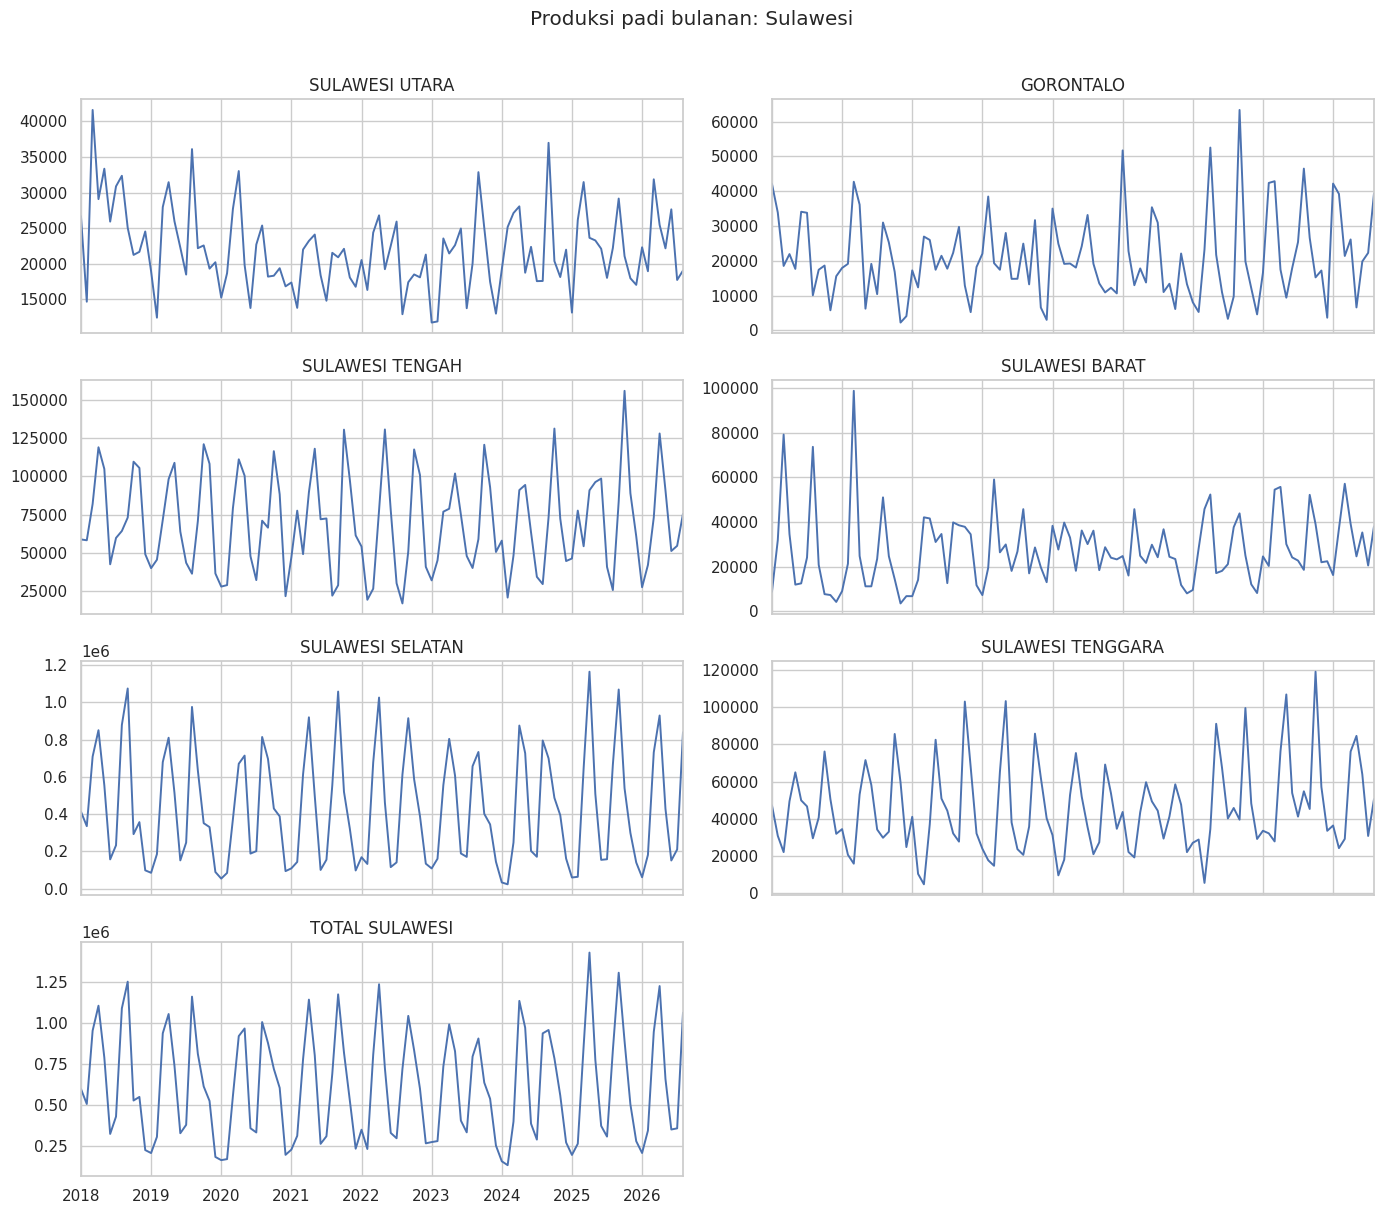

In [5]:
import math
fig, axes = plt.subplots(math.ceil(len(MODEL_PROV)/2),2,figsize=(14,12),sharex=True)
for ax,p in zip(axes.ravel(),MODEL_PROV):
    data[TARGET][p].plot(ax=ax,lw=1.4); ax.set_title(p); ax.set_xlabel("")
for ax in axes.ravel()[len(MODEL_PROV):]:ax.axis("off")
fig.suptitle(f"Produksi padi bulanan: {PULAU_PILIH}",y=1.01)
plt.tight_layout();plt.show()

### 2.3 Pola musiman

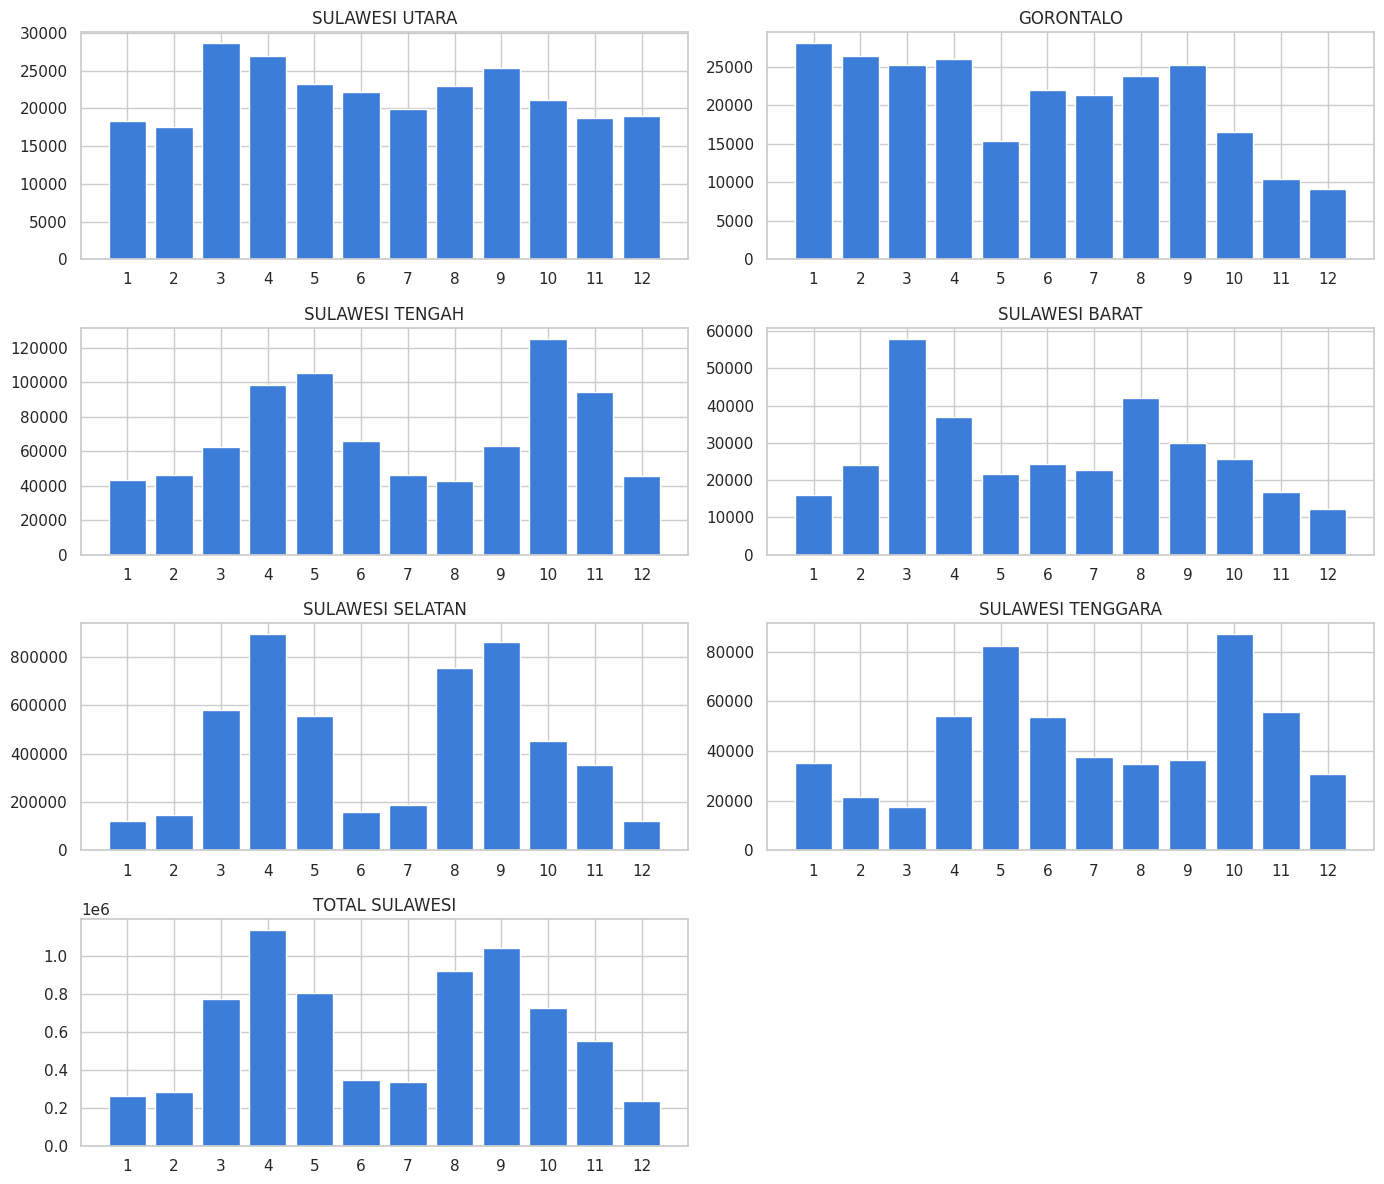

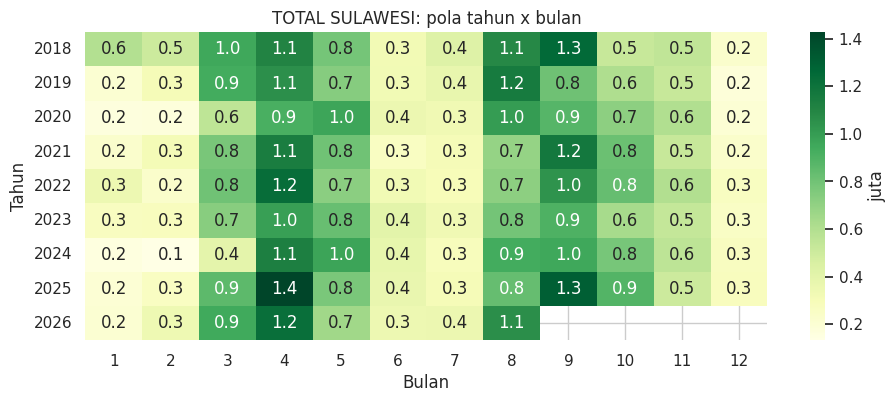

In [6]:
fig, axes = plt.subplots(math.ceil(len(MODEL_PROV)/2),2,figsize=(14,12))
for ax,p in zip(axes.ravel(),MODEL_PROV):
    s = data[TARGET][p]
    tab = s.groupby(s.index.month).mean()
    ax.bar(tab.index,tab.values,color="#3b7dd8");ax.set_title(p);ax.set_xticks(range(1,13))
for ax in axes.ravel()[len(MODEL_PROV):]:ax.axis("off")
plt.tight_layout();plt.show()
t=data[TARGET][TOTAL]
hm=t.to_frame("v").assign(Tahun=t.index.year,Bulan=t.index.month).pivot(index="Tahun",columns="Bulan",values="v")
plt.figure(figsize=(11,4));sns.heatmap(hm/1e6,cmap="YlGn",annot=True,fmt=".1f",cbar_kws={"label":"juta"})
plt.title(f"{TOTAL}: pola tahun x bulan");plt.show()

### 2.4 Pemeriksaan kestabilan ragam (profil likelihood Box–Cox)

Box–Cox dipakai sebagai **diagnostik dan upaya stabilisasi ragam Y** sebelum uji stasioneritas dalam rataan. Perhitungan menggunakan **Y data latih saja** (setelah 6 bulan pertama dikeluarkan agar sesuai dengan awal model). Karena produksi padi bernilai nonnegatif, gunakan **`shift = 1` secara konsisten** pada semua seri yang perlu ditransformasi. Ini juga mencegah kegagalan saat nilai nol baru muncul pada data uji.

\[
BC(y;\lambda)=\begin{cases}
\dfrac{(y+c)^\lambda-1}{\lambda}, &\lambda\ne 0 \\
\ln(y+c), &\lambda=0.
\end{cases}
\]

Periksa kurva profil log-likelihood Box–Cox, \(\hat\lambda\), dan CI 95%. **Jika 1 termasuk CI 95% λ, pertahankan Y asli; jika 1 tidak termasuk CI, gunakan transformasi Box–Cox dengan λ estimasi.** Ini aturan kerja berbasis CI λ dalam asumsi model Box–Cox, **bukan uji formal stasioneritas ragam** atau jaminan varian residual konstan. Pengujian heteroskedastisitas residual merupakan pemeriksaan tambahan setelah model. Semua keputusan diterapkan per provinsi, termasuk agregat Sulawesi.

,Lambda_hat,CI_bawah,CI_atas,Skala_internal,Shift,Lambda_dipakai,Transformasi,Keputusan
Provinsi,,,,,,,,
SULAWESI UTARA,0.1774,-0.5231,0.8788,1.4809,1.0,0.1774,Box-Cox,CI tidak memuat 1: transformasi
GORONTALO,0.3438,0.0802,0.6169,18.1985,1.0,0.3438,Box-Cox,CI tidak memuat 1: transformasi
SULAWESI TENGAH,0.4880,0.0622,0.9306,107.2171,1.0,0.4880,Box-Cox,CI tidak memuat 1: transformasi
SULAWESI BARAT,0.2981,0.0227,0.5766,12.2329,1.0,0.2981,Box-Cox,CI tidak memuat 1: transformasi
SULAWESI SELATAN,0.3102,0.0598,0.5764,43.5772,1.0,0.3102,Box-Cox,CI tidak memuat 1: transformasi
SULAWESI TENGGARA,0.4316,0.1556,0.7297,53.8449,1.0,0.4316,Box-Cox,CI tidak memuat 1: transformasi
TOTAL SULAWESI,0.3095,-0.0823,0.7104,35.4391,1.0,0.3095,Box-Cox,CI tidak memuat 1: transformasi


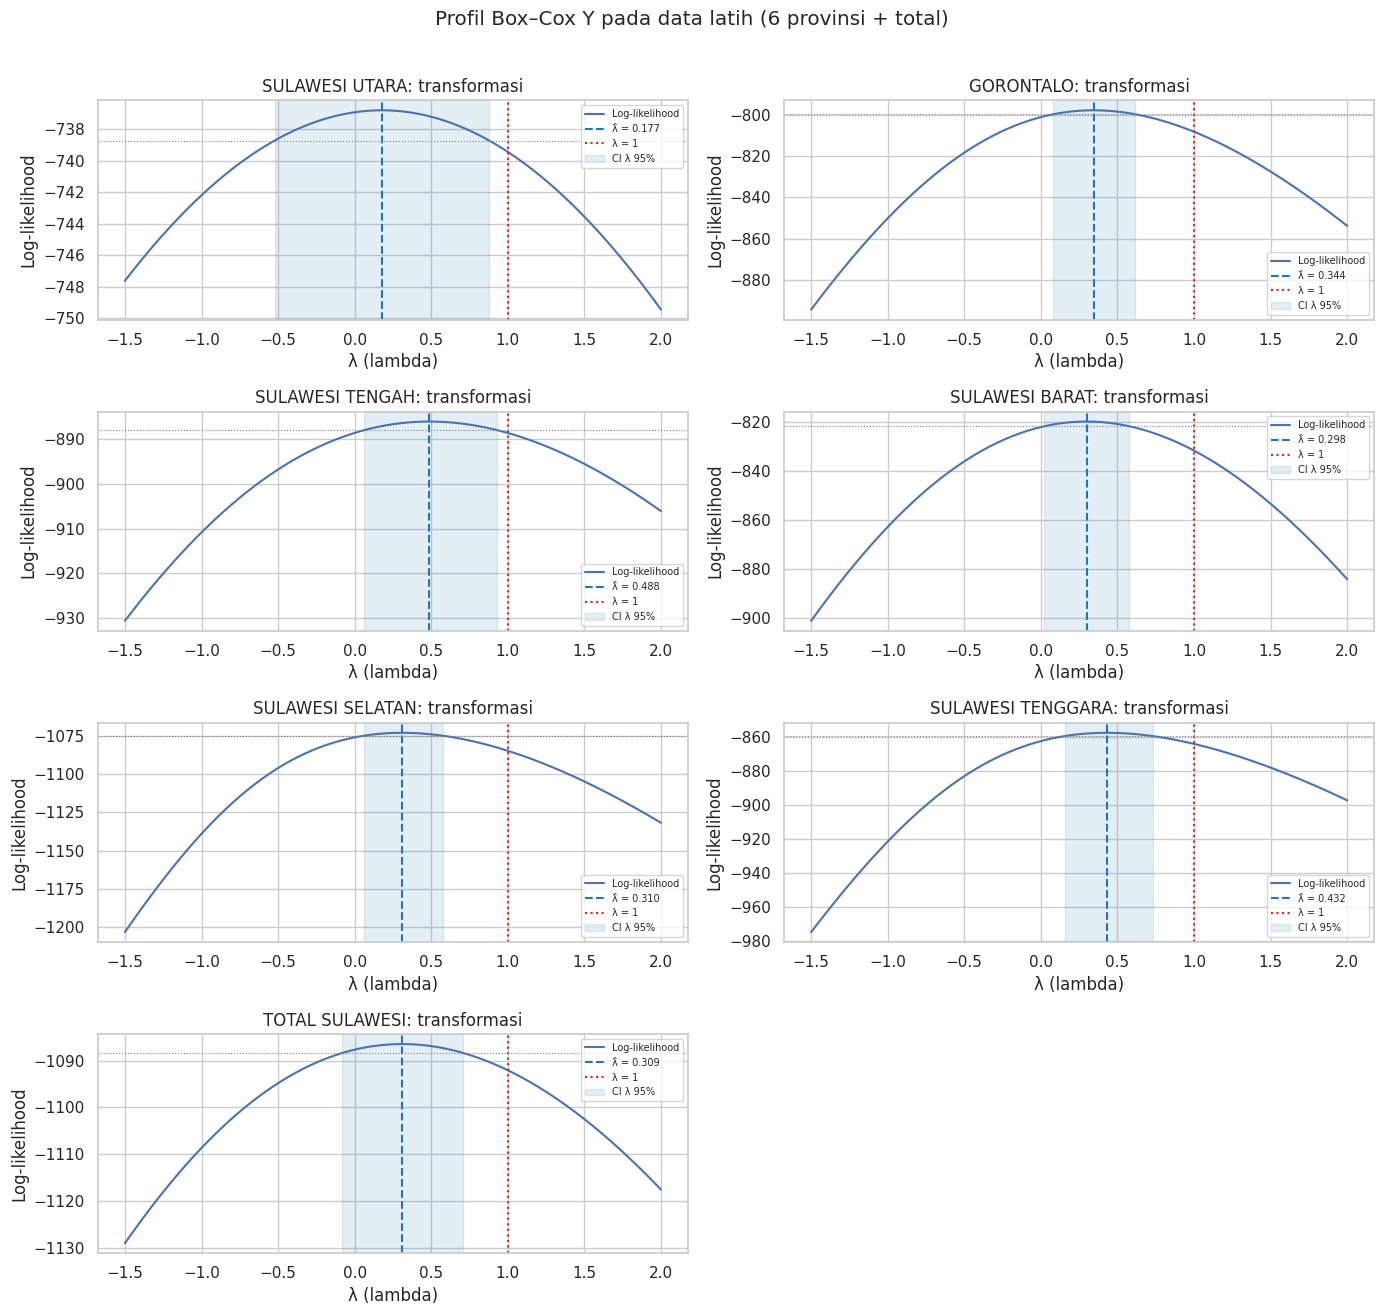

In [7]:
from scipy.stats import boxcox as stats_boxcox, boxcox_llf, chi2
from scipy.special import boxcox as special_boxcox, inv_boxcox

boxcox_status={}; boxcox_rows=[]
for p in MODEL_PROV:
    train=data[TARGET][p].iloc[START_LAG:-TEST].astype(float)
    assert len(train)>=36 and train.nunique()>=3, f"Data Y tidak memadai untuk Box-Cox: {p}"
    shift=float(BOXCOX_SHIFT_ZERO)  # tambah 1 pada semua seri, termasuk jika data latih tidak mengandung nol
    arr=train.to_numpy()+shift
    assert np.all(arr>0)
    _,lam_hat,ci=stats_boxcox(arr,alpha=BOXCOX_ALPHA)
    lo,hi=map(float,ci)
    perform=(not(lo<=1.0<=hi))
    train_transformed = special_boxcox(arr,lam_hat) if perform else train.to_numpy()
    scale = float(np.std(train_transformed,ddof=1))
    if not np.isfinite(scale) or scale <= 0: scale = 1.0
    boxcox_status[p]={"Lambda_hat":float(lam_hat), "CI_bawah":lo,"CI_atas":hi,
                      "Skala_internal":scale,
                      "Shift":shift,"Lambda_dipakai":float(lam_hat) if perform else 1.0,
                      "Transformasi":"Box-Cox" if perform else "Tidak (Y asli)"}
    boxcox_rows.append({"Provinsi":p,**boxcox_status[p],
                        "Keputusan":"CI tidak memuat 1: transformasi" if perform else "CI memuat 1: tanpa transformasi"})
tabel_boxcox=pd.DataFrame(boxcox_rows).set_index("Provinsi")
display(tabel_boxcox.round(4))

def transform_y(s,p):
    """Gunakan Box-Cox Y hanya bila CI 95% lambda dari data LATIH tak memuat 1."""
    s=s.astype(float).copy()
    cfg=boxcox_status[p]
    if cfg["Transformasi"]=="Box-Cox":
        shifted=s+cfg["Shift"]
        if not (shifted>0).all():
            raise ValueError(f"Nilai Y di luar domain Box-Cox {p}; periksa shift dan data uji")
        return pd.Series(special_boxcox(shifted.to_numpy(),cfg["Lambda_dipakai"])/cfg["Skala_internal"],index=s.index,name=s.name)
    return s / cfg["Skala_internal"]

# Profil log-likelihood tiap provinsi: garis biru = lambda-hat,
# merah = lambda 1 (tanpa transformasi), arsiran = CI 95%.
fig,axes=plt.subplots(math.ceil(len(MODEL_PROV)/2),2,figsize=(14,13))
for ax,p in zip(axes.ravel(),MODEL_PROV):
    cfg=boxcox_status[p]
    arr=data[TARGET][p].iloc[START_LAG:-TEST].to_numpy()+cfg["Shift"]
    lm=cfg["Lambda_hat"];lo=cfg["CI_bawah"];hi=cfg["CI_atas"]
    a=min(-1.5,lm-1.0,lo-.25,1-.5);b=max(2.0,lm+1.0,hi+.25,1+.5)
    candidates=np.linspace(a,b,300)
    ll=np.array([boxcox_llf(lam,arr) for lam in candidates])
    llpeak=boxcox_llf(lm,arr)
    threshold=llpeak-0.5*chi2.ppf(1-BOXCOX_ALPHA,df=1)
    ax.plot(candidates,ll,label="Log-likelihood")
    ax.axvline(lm,color="tab:blue",ls="--",label=f"λ̂ = {lm:.3f}")
    ax.axvline(1,color="tab:red",ls=":",label="λ = 1")
    ax.axhline(threshold,color="grey",ls=":",lw=.8)
    ax.axvspan(lo,hi,color="tab:blue",alpha=.12,label="CI λ 95%")
    ax.set_title(f"{p}: {'transformasi' if cfg['Transformasi']=='Box-Cox' else 'tanpa transformasi'}")
    ax.set_xlabel("λ (lambda)");ax.set_ylabel("Log-likelihood")
    ax.legend(fontsize=7,loc="best")
for ax in axes.ravel()[len(MODEL_PROV):]:ax.axis("off")
plt.suptitle("Profil Box–Cox Y pada data latih (6 provinsi + total)",y=1.01)
plt.tight_layout();plt.show()

**Pemeriksaan visual sebelum/sesudah transformasi:** plot di bawah memperlihatkan deret Y asli dan hasil Box–Cox pada **data latih** untuk semua provinsi. Jika CI mencakup 1, panel hasil tetap dalam skala asli. Skala sumbu kanan dan kiri **tidak sama** (hasil transformasi juga diskalakan dengan simpangan baku latih), sehingga bandingkan pola variasi, bukan amplitudo absolut antarskala.

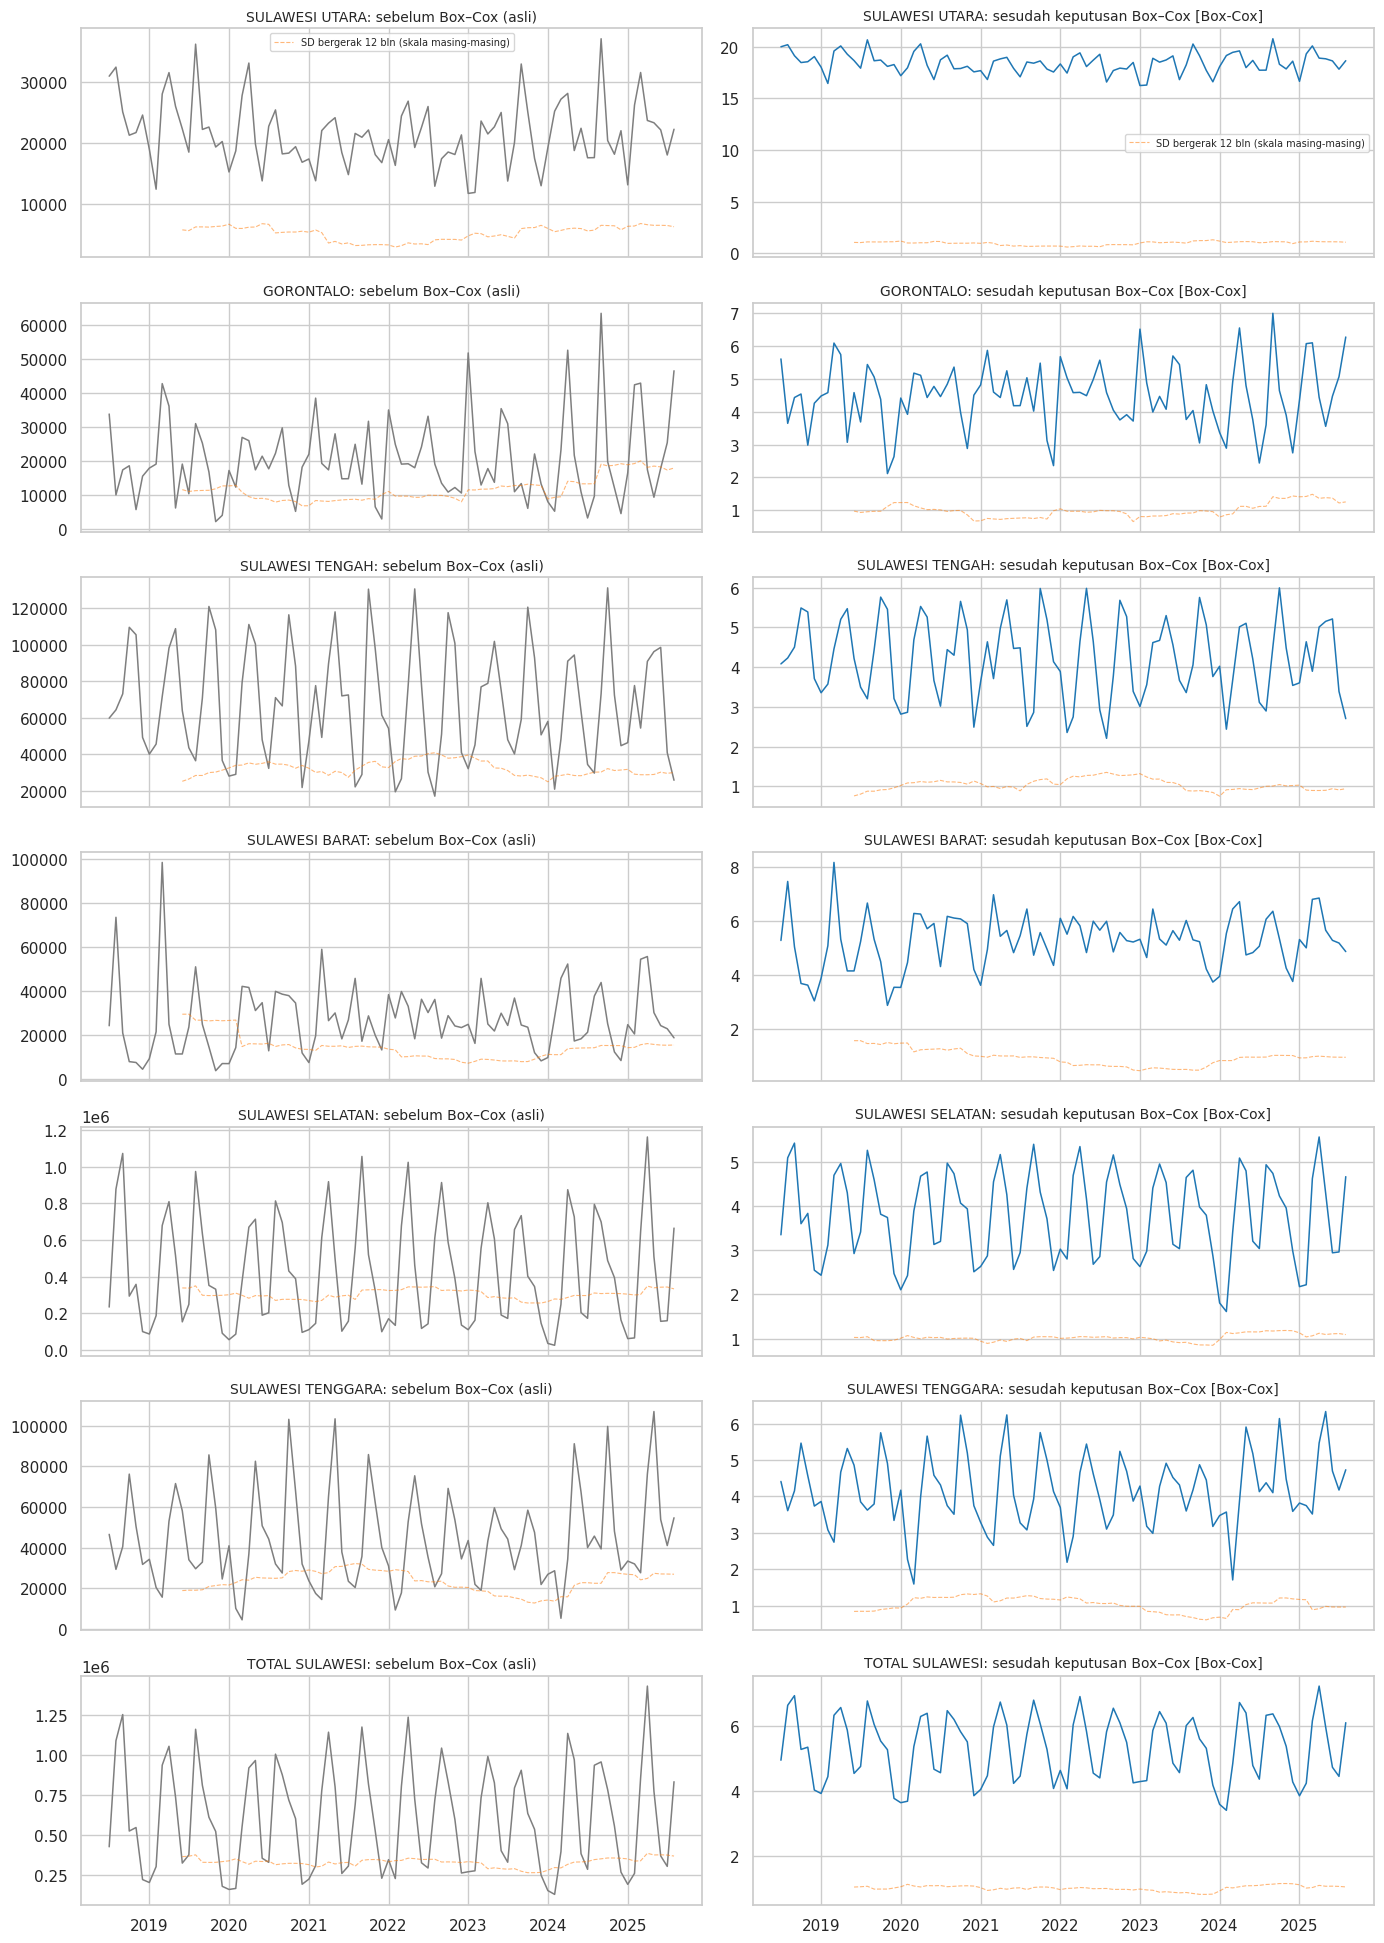

In [8]:
fig,axes=plt.subplots(len(MODEL_PROV),2,figsize=(14,2.8*len(MODEL_PROV)),sharex=True)
for i,p in enumerate(MODEL_PROV):
    z=data[TARGET][p].iloc[START_LAG:-TEST]
    zt=transform_y(z,p)
    axes[i,0].plot(z.index,z,color="tab:gray",lw=1.1)
    axes[i,0].set_title(f"{p}: sebelum Box–Cox (asli)",fontsize=10)
    axes[i,1].plot(zt.index,zt,color="tab:blue",lw=1.1)
    axes[i,1].set_title(f"{p}: sesudah keputusan Box–Cox [{boxcox_status[p]['Transformasi']}]",fontsize=10)
    for j,v in [(0,z),(1,zt)]:
        r=v.rolling(12,min_periods=12).std()
        axes[i,j].plot(r.index,r,color="tab:orange",alpha=.55,lw=.8,ls="--",
                       label="SD bergerak 12 bln (skala masing-masing)")
        if i==0:axes[i,j].legend(fontsize=7)
plt.tight_layout();plt.show()

### 2.5 Dekomposisi STL dan kekuatan musiman/tren (Y setelah keputusan Box–Cox)

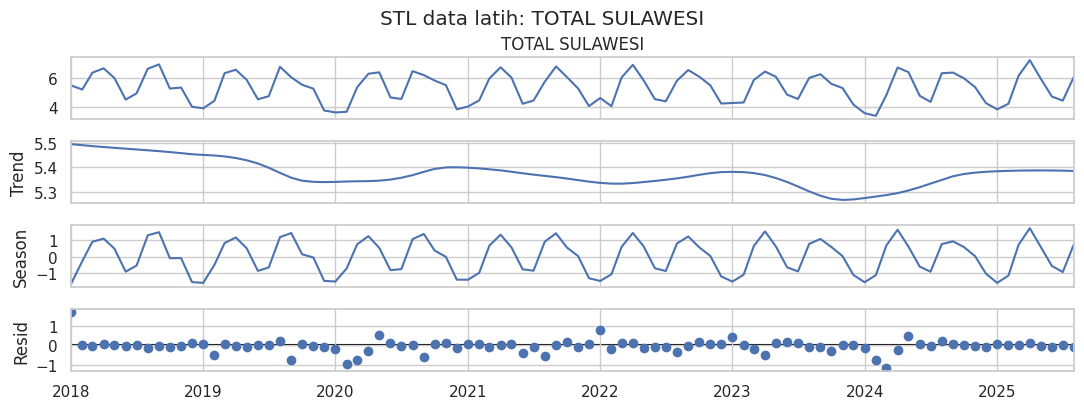

,Kekuatan tren,Kekuatan musiman
Provinsi,,
SULAWESI UTARA,0.356,0.625
GORONTALO,0.086,0.400
SULAWESI TENGAH,0.060,0.769
SULAWESI BARAT,0.060,0.735
SULAWESI SELATAN,0.092,0.899
SULAWESI TENGGARA,0.114,0.837
TOTAL SULAWESI,0.095,0.888


In [9]:
rows=[]; strength={}
for p in MODEL_PROV:
    s=data[TARGET][p].iloc[:-TEST] # hanya latih untuk keputusan model
    s=transform_y(s,p)
    r=STL(s,period=S,robust=True).fit()
    Ft=max(0,1-r.resid.var()/(r.trend+r.resid).var())
    Fs=max(0,1-r.resid.var()/(r.seasonal+r.resid).var())
    strength[p]=Fs
    rows.append([p,Ft,Fs])
    if p==TOTAL:r.plot();plt.suptitle(f"STL data latih: {TOTAL}",y=1.02);plt.show()
tabel_stl=pd.DataFrame(rows,columns=["Provinsi","Kekuatan tren","Kekuatan musiman"]).set_index("Provinsi")
display(tabel_stl.round(3))

Nilai kekuatan musiman STL mendekati 1 berarti pola musiman kuat, **bukan bukti akar unit musiman**. Jangan secara otomatis menetapkan D=1 hanya karena kekuatan musiman besar. Semua diagnostik pemilihan model memakai **data latih**.

### 2.6 Korelasi silang dan pemilihan lag kedua eksogen (berdasarkan data latih)

,Corr Y-X1 lag 0,Corr Y-Hujan lag 0
Provinsi,,
SULAWESI UTARA,0.949,-0.194
GORONTALO,0.988,0.005
SULAWESI TENGAH,0.996,-0.019
SULAWESI BARAT,0.990,-0.069
SULAWESI SELATAN,0.995,-0.092
SULAWESI TENGGARA,0.987,-0.093
TOTAL SULAWESI,0.995,-0.007


Korelasi silang Y terhadap X1 (lag 0–6):


Lag,0,1,2,3,4,5,6
Provinsi,,,,,,,
GORONTALO,0.977,-0.153,-0.325,-0.239,-0.086,0.545,0.087
SULAWESI BARAT,0.976,-0.372,-0.047,-0.172,-0.038,0.129,0.221
SULAWESI SELATAN,0.907,0.046,-0.135,-0.205,-0.096,0.097,0.091
SULAWESI TENGAH,0.988,-0.185,-0.420,-0.064,-0.074,0.440,0.160
SULAWESI TENGGARA,0.928,-0.189,-0.168,-0.039,-0.077,-0.058,0.203
SULAWESI UTARA,0.984,-0.447,-0.104,0.064,-0.206,0.356,0.045
TOTAL SULAWESI,0.970,-0.125,-0.170,-0.064,-0.059,0.055,0.107


Korelasi silang Y terhadap X2 (lag 0–6):


Lag,0,1,2,3,4,5,6
Provinsi,,,,,,,
GORONTALO,-0.044,-0.209,-0.035,0.092,0.071,0.200,-0.143
SULAWESI BARAT,-0.231,-0.117,0.120,0.127,-0.017,0.076,-0.205
SULAWESI SELATAN,-0.069,0.089,-0.010,-0.113,0.359,0.010,-0.017
SULAWESI TENGAH,-0.200,0.063,0.101,-0.137,0.143,0.020,-0.133
SULAWESI TENGGARA,-0.071,0.205,-0.201,0.137,0.025,0.250,-0.309
SULAWESI UTARA,-0.059,-0.089,0.245,-0.301,0.286,-0.005,-0.360
TOTAL SULAWESI,-0.127,0.120,0.094,-0.295,0.382,0.062,-0.133


Lag terpilih pada setiap provinsi dan variabel (berdasarkan data latih):


Lag terpilih  Korelasi pada lag  \
Provinsi          Variabel                                    
SULAWESI UTARA    X1                   0              0.984   
                  X2                   6             -0.360   
GORONTALO         X1                   0              0.977   
                  X2                   1             -0.209   
SULAWESI TENGAH   X1                   0              0.988   
                  X2                   0             -0.200   
SULAWESI BARAT    X1                   0              0.976   
                  X2                   0             -0.231   
SULAWESI SELATAN  X1                   0              0.907   
                  X2                   4              0.359   
SULAWESI TENGGARA X1                   0              0.928   
                  X2                   6             -0.309   
TOTAL SULAWESI    X1                   0              0.970   
                  X2                   4              0.382   

                                                   Peringatan  
Provinsi          Variabel                                     
SULAWESI UTARA    X1                                           
                  X2                                           
GORONTALO         X1                                           
                  X2        CCF lemah; uji ulang via validasi  
SULAWESI TENGAH   X1                                           
                  X2        CCF lemah; uji ulang via validasi  
SULAWESI BARAT    X1                                           
                  X2        CCF lemah; uji ulang via validasi  
SULAWESI SELATAN  X1                                           
                  X2                                           
SULAWESI TENGGARA X1                                           
                  X2                                           
TOTAL SULAWESI    X1                                           
                  X2

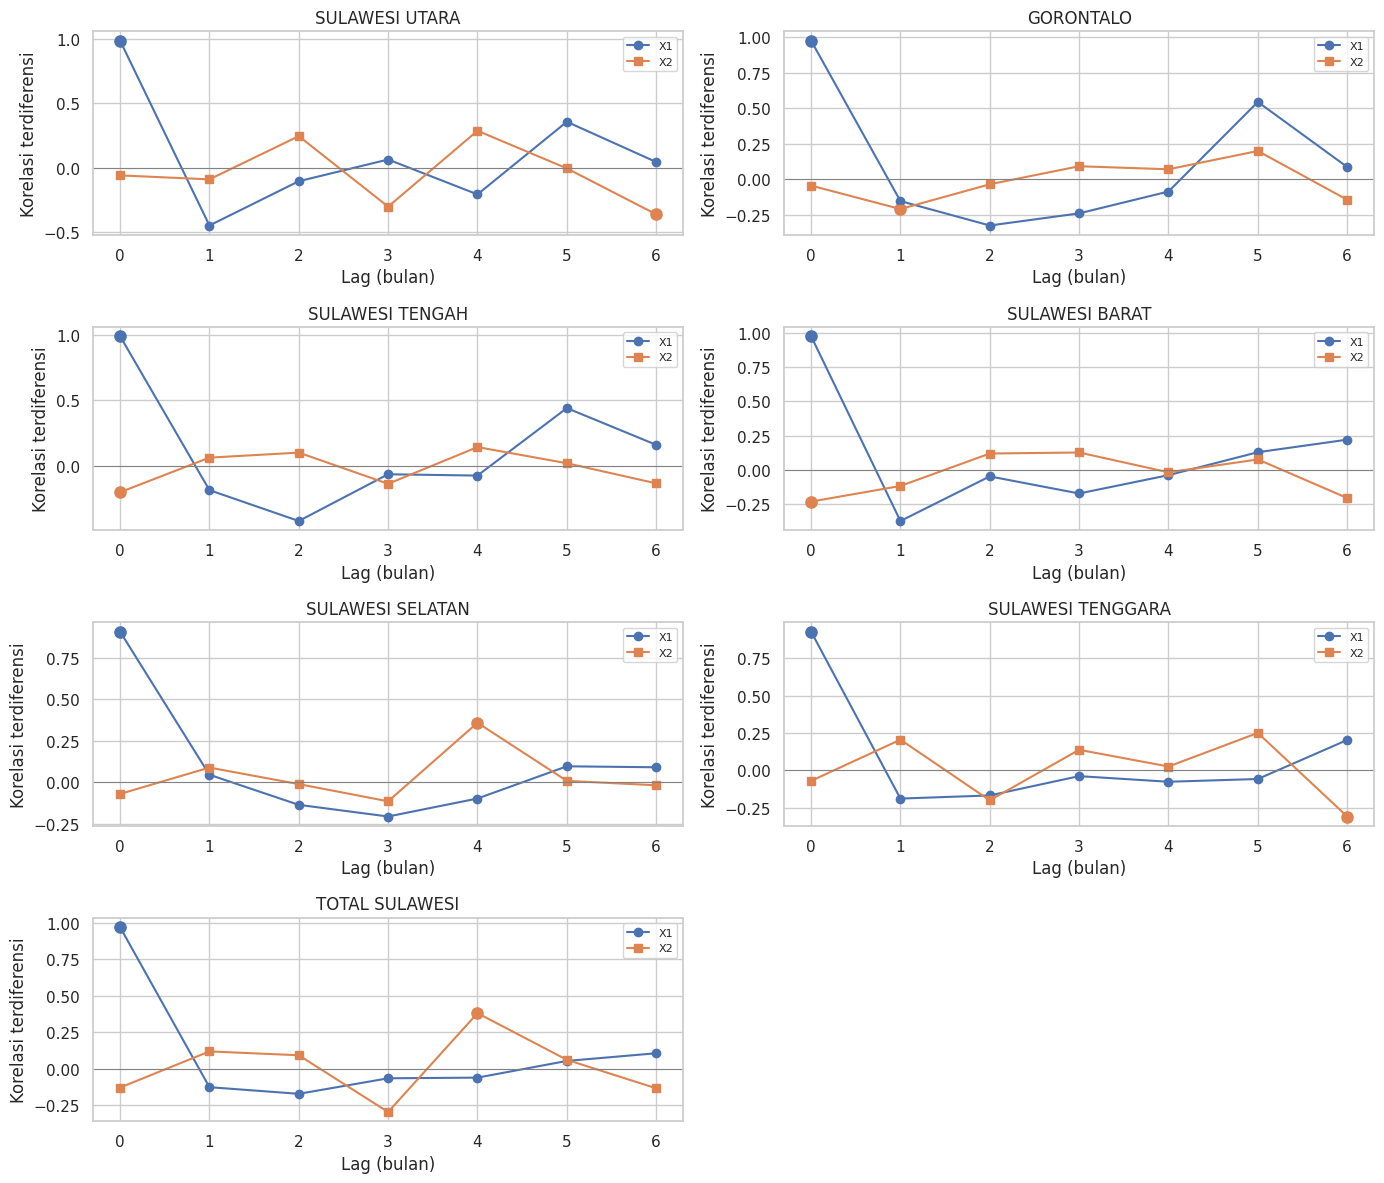

In [10]:
# Pilih lag terbaik pada rentang 0..MAX_LAG untuk KEDUA variabel eksogen.
# Korelasi dilakukan pada deret yang didifferencing 1 kali dan musiman 12 kali.
# Box-Cox Y sudah ditetapkan menggunakan data latih; X1 dan X2 memakai log1p.
kor=[]; lagrows=[]
for p in MODEL_PROV:
    d=pd.DataFrame({c:data[c][p].iloc[:-TEST] for c in [TARGET]+EXOG})
    kor.append({"Provinsi":p,"Corr Y-X1 lag 0":d[TARGET].corr(d["X1"]),
                "Corr Y-Hujan lag 0":d[TARGET].corr(d["X2"])})
    yy=transform_y(d[TARGET],p).diff(S).diff()
    for c in EXOG:
        xx=np.log1p(d[c]).diff(S).diff()
        for lag in range(MAX_LAG+1):
            r=yy.corr(xx.shift(lag))
            lagrows.append({"Provinsi":p,"Variabel":c,"Lag":lag,
                            "Corr_terdiferensi":r, "|Corr|":abs(r) if np.isfinite(r) else np.nan})
kor=pd.DataFrame(kor).set_index("Provinsi")
tabel_lag=pd.DataFrame(lagrows)
display(kor.round(3))
for c in EXOG:
    print(f"Korelasi silang Y terhadap {c} (lag 0–{MAX_LAG}):")
    display(tabel_lag[tabel_lag.Variabel==c].pivot(index="Provinsi",columns="Lag",values="Corr_terdiferensi").round(3))
lag_terpilih={}; selected_rows=[]
for p in MODEL_PROV:
    lag_terpilih[p]={}
    for c in EXOG:
        if AUTO_LAG:
            a=tabel_lag[(tabel_lag.Provinsi==p)&(tabel_lag.Variabel==c)].dropna(subset=["Corr_terdiferensi"])
            if a.empty: raise RuntimeError(f"CCF tidak dapat dihitung untuk {p} / {c}")
            row=a.loc[a["|Corr|"].idxmax()]
            lag=int(row.Lag); corr=float(row.Corr_terdiferensi)
        else:
            lag=int(LAG_MANUAL[c])
            a=tabel_lag[(tabel_lag.Provinsi==p)&(tabel_lag.Variabel==c)&(tabel_lag.Lag==lag)]
            corr=float(a.iloc[0].Corr_terdiferensi)
        assert 0<=lag<=START_LAG
        lag_terpilih[p][c]=lag
        selected_rows.append({"Provinsi":p,"Variabel":c,"Lag terpilih":lag,
                              "Korelasi pada lag":corr,
                              "Peringatan": "CCF lemah; uji ulang via validasi" if abs(corr)<MIN_ABS_CCF else ""})
tabel_lag_pilih=pd.DataFrame(selected_rows).set_index(["Provinsi","Variabel"])
print("Lag terpilih pada setiap provinsi dan variabel (berdasarkan data latih):")
display(tabel_lag_pilih.round(3))

fig,axes=plt.subplots(math.ceil(len(MODEL_PROV)/2),2,figsize=(14,12))
for ax,p in zip(axes.ravel(),MODEL_PROV):
    for c,mark in [("X1","o"),("X2","s")]:
        z=tabel_lag[(tabel_lag.Provinsi==p)&(tabel_lag.Variabel==c)]
        ax.plot(z.Lag,z.Corr_terdiferensi,marker=mark,label=c)
        ax.scatter(lag_terpilih[p][c],
                   z.loc[z.Lag==lag_terpilih[p][c],"Corr_terdiferensi"].iloc[0],s=65)
    ax.axhline(0,color="grey",lw=.7);ax.set_xticks(range(MAX_LAG+1))
    ax.set_title(p);ax.set_xlabel("Lag (bulan)");ax.set_ylabel("Korelasi terdiferensi")
    ax.legend(fontsize=8)
for ax in axes.ravel()[len(MODEL_PROV):]: ax.axis("off")
plt.tight_layout();plt.show()


**Interpretasi:** `lag X1 = k₁` berarti luas panen bulan t−k₁ digunakan untuk menjelaskan produksi t; `lag hujan = k₂` demikian pula. **Keduanya diperlakukan sama**, dengan rentang kandidat 0–6. Lag 0 tetap bisa terpilih, tetapi **berdasarkan data, bukan ditetapkan di awal**. Korelasi terbesar setelah differencing adalah petunjuk eksploratif; CCF dapat dipengaruhi autokorelasi, trend, dan hubungan simultan, sehingga lag sebaiknya dikonfirmasi lewat validasi temporal tambahan. Korelasi absolut yang kecil diberi penanda, **bukan** otomatis dipaksa menjadi lag 0. Untuk peramalan ex-ante, variabel eksogen yang belum teramati tetap harus diproyeksikan.

## 3. Uji Stasioneritas dalam Rataan dan Penanganan Differencing

Sesudah menentukan kestabilan ragam dengan profil Box–Cox, uji ADF/KPSS dilakukan terhadap **Y pada skala hasil keputusan Box–Cox**. Empat kombinasi `d,D = (0,0), (1,0), (0,1), (1,1)` diperiksa **hanya pada data latih**.
- **ADF:** H₀ = terdapat akar unit. Nilai p < 0,05 mendukung stasioneritas.
- **KPSS:** H₀ = stasioner. Nilai p > 0,05 berarti tidak ada bukti cukup untuk menolak stasioneritas.

ADF/KPSS standar **tidak secara langsung** membuktikan ada/tidaknya akar unit musiman; cek ACF/PACF, AIC, dan diagnostik. Keputusan Box–Cox **tidak** menjamin ragam konstan; profil likelihood Box–Cox terutama mendasarkan estimasi λ pada asumsi normalitas data transformasi.

In [11]:
from statsmodels.tools.sm_exceptions import InterpolationWarning, ConvergenceWarning

def differencing(s,d,D):
    z=s.diff(S).dropna() if D else s.copy()
    return z.diff().dropna() if d else z

def uji(s):
    x=s.dropna()
    if len(x)<24 or x.nunique()<3:
        return {"ADF p":np.nan,"KPSS p":np.nan,"Lulus keduanya":False}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore",InterpolationWarning)
        try:a=adfuller(x,autolag="AIC")[1]
        except Exception:a=np.nan
        try:k=kpss(x,regression="c",nlags="auto")[1]
        except Exception:k=np.nan
    return {"ADF p":a,"KPSS p":k,
            "Lulus keduanya":bool(np.isfinite(a) and np.isfinite(k) and a<.05 and k>.05)}

tahap={};hasil=[];status_uji={}
for p in MODEL_PROV:
    z=transform_y(data[TARGET][p].iloc[START_LAG:-TEST],p)
    tahap[p]={}
    for d,D in [(0,0),(1,0),(0,1),(1,1)]:
        zz=differencing(z,d,D)
        tahap[p][(d,D)]=zz
        r=uji(zz)
        status_uji[(p,d,D)]=r
        hasil.append({"Provinsi":p,"d":d,"D":D,"N":len(zz),**r})
tabel_stas=pd.DataFrame(hasil).set_index(["Provinsi","d","D"])
display(tabel_stas.round(4))

N   ADF p  KPSS p  Lulus keduanya
Provinsi          d D                                    
SULAWESI UTARA    0 0  86  0.0045  0.1000            True
                  1 0  85  0.0000  0.1000            True
                  0 1  74  0.1480  0.0451           False
                  1 1  73  0.0561  0.1000           False
GORONTALO         0 0  86  0.0002  0.1000            True
                  1 0  85  0.0000  0.0952            True
                  0 1  74  0.0094  0.1000            True
                  1 1  73  0.0000  0.1000            True
SULAWESI TENGAH   0 0  86  0.0583  0.1000           False
                  1 0  85  0.0000  0.1000            True
                  0 1  74  0.0024  0.1000            True
                  1 1  73  0.1391  0.1000           False
SULAWESI BARAT    0 0  86  0.3015  0.1000           False
                  1 0  85  0.0000  0.1000            True
                  0 1  74  0.1820  0.1000           False
                  1 1  73  0.0091  0.1000            True
SULAWESI SELATAN  0 0  86  0.0826  0.1000           False
                  1 0  85  0.0001  0.1000            True
                  0 1  74  0.0000  0.1000            True
                  1 1  73  0.0000  0.1000            True
SULAWESI TENGGARA 0 0  86  0.9222  0.1000           False
                  1 0  85  0.0000  0.1000            True
                  0 1  74  0.0000  0.1000            True
                  1 1  73  0.0421  0.1000            True
TOTAL SULAWESI    0 0  86  0.1840  0.1000           False
                  1 0  85  0.0000  0.1000            True
                  0 1  74  0.0040  0.1000            True
                  1 1  73  0.0333  0.0417           False

### 3.1 Menentukan d dan D secara otomatis

In [12]:
# Parsimoni: D tidak ditetapkan otomatis hanya dari kekuatan musiman.
# Bila ada beberapa kombinasi lulus ADF dan KPSS, kekuatan STL hanya menjadi
# petunjuk preferensi antara (0,1) dan (1,0); utamakan (0,0) jika sudah cukup.
orde_dD={}
for p in MODEL_PROV:
    prioritas=([(0,0),(0,1),(1,0),(1,1)] if strength[p]>=.64
               else [(0,0),(1,0),(0,1),(1,1)])
    valid=[(d,D) for d,D in prioritas if status_uji[(p,d,D)]["Lulus keduanya"]]
    if valid:
        chosen=valid[0];catatan="ADF/KPSS mendukung (heuristik)"
    else:
        by_adf=[(d,D) for d,D in prioritas if status_uji[(p,d,D)]["ADF p"]<.05]
        chosen=by_adf[0] if by_adf else (1,1)
        catatan="ADF/KPSS konflik; periksa manual"
    orde_dD[p]=chosen
    print(f"{p:20s} d={chosen[0]} D={chosen[1]} | {catatan}")
tabel_orde=pd.DataFrame(orde_dD,index=["d","D"]).T

SULAWESI UTARA       d=0 D=0 | ADF/KPSS mendukung (heuristik)
GORONTALO            d=0 D=0 | ADF/KPSS mendukung (heuristik)
SULAWESI TENGAH      d=0 D=1 | ADF/KPSS mendukung (heuristik)
SULAWESI BARAT       d=1 D=0 | ADF/KPSS mendukung (heuristik)
SULAWESI SELATAN     d=0 D=1 | ADF/KPSS mendukung (heuristik)
SULAWESI TENGGARA    d=0 D=1 | ADF/KPSS mendukung (heuristik)
TOTAL SULAWESI       d=0 D=1 | ADF/KPSS mendukung (heuristik)


**Catatan:** penentuan d dan D di atas adalah prosedur heuristik awal pada data latih, bukan keputusan universal. Kekuatan musiman STL bukan uji akar unit musiman. Periksa ACF/PACF dan diagnostik residual, dan bandingkan kombinasi d,D alternatif jika terdapat ketidakjelasan.

### 3.2 Visual differencing + identifikasi ACF/PACF

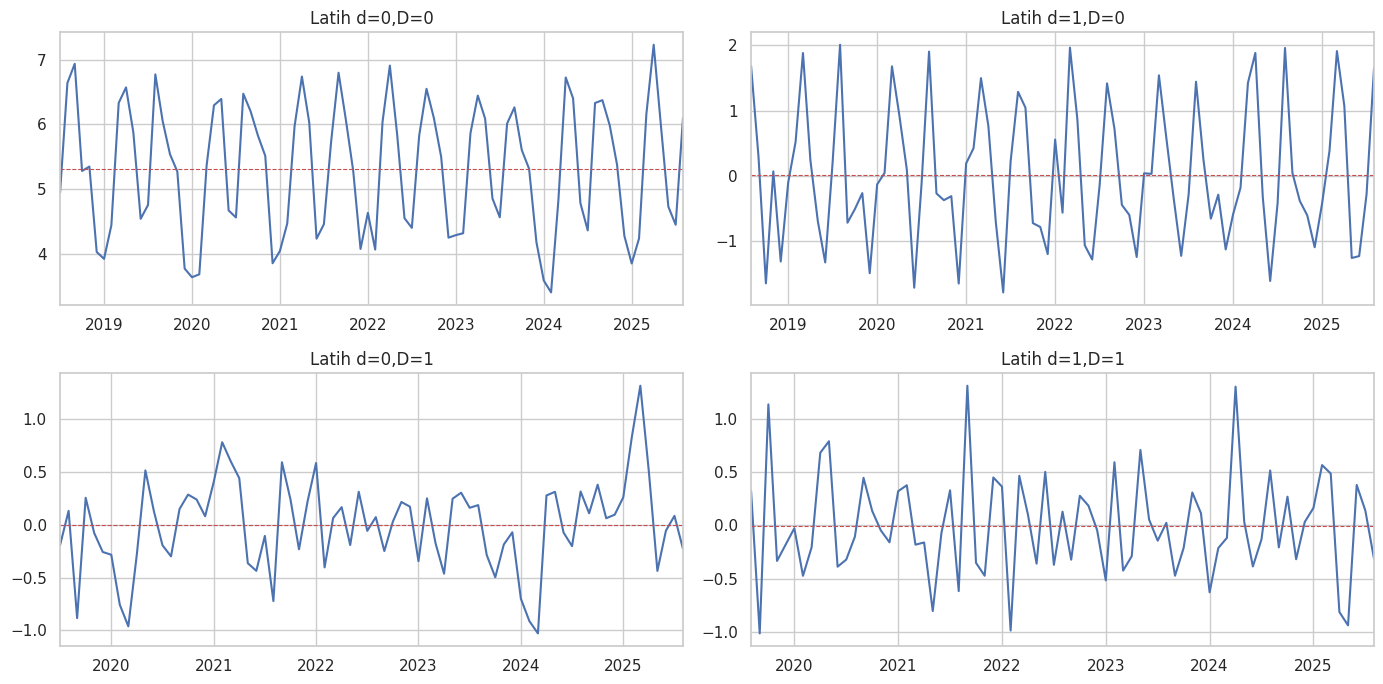

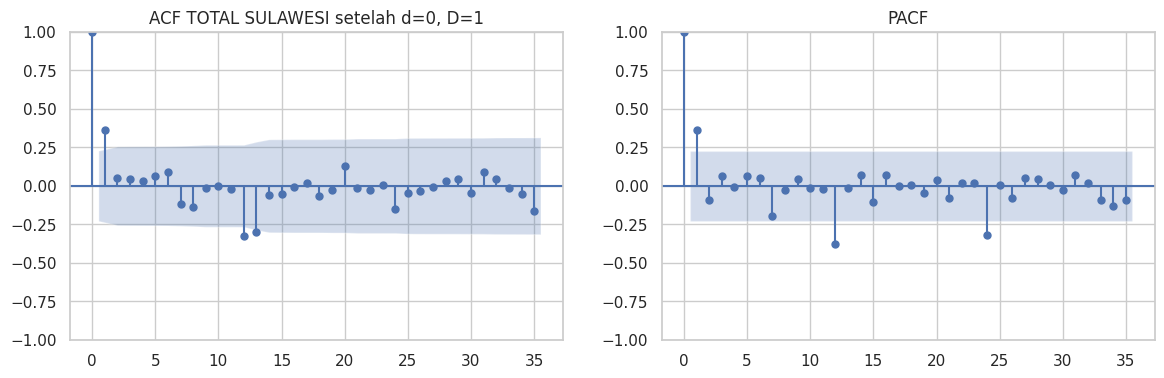

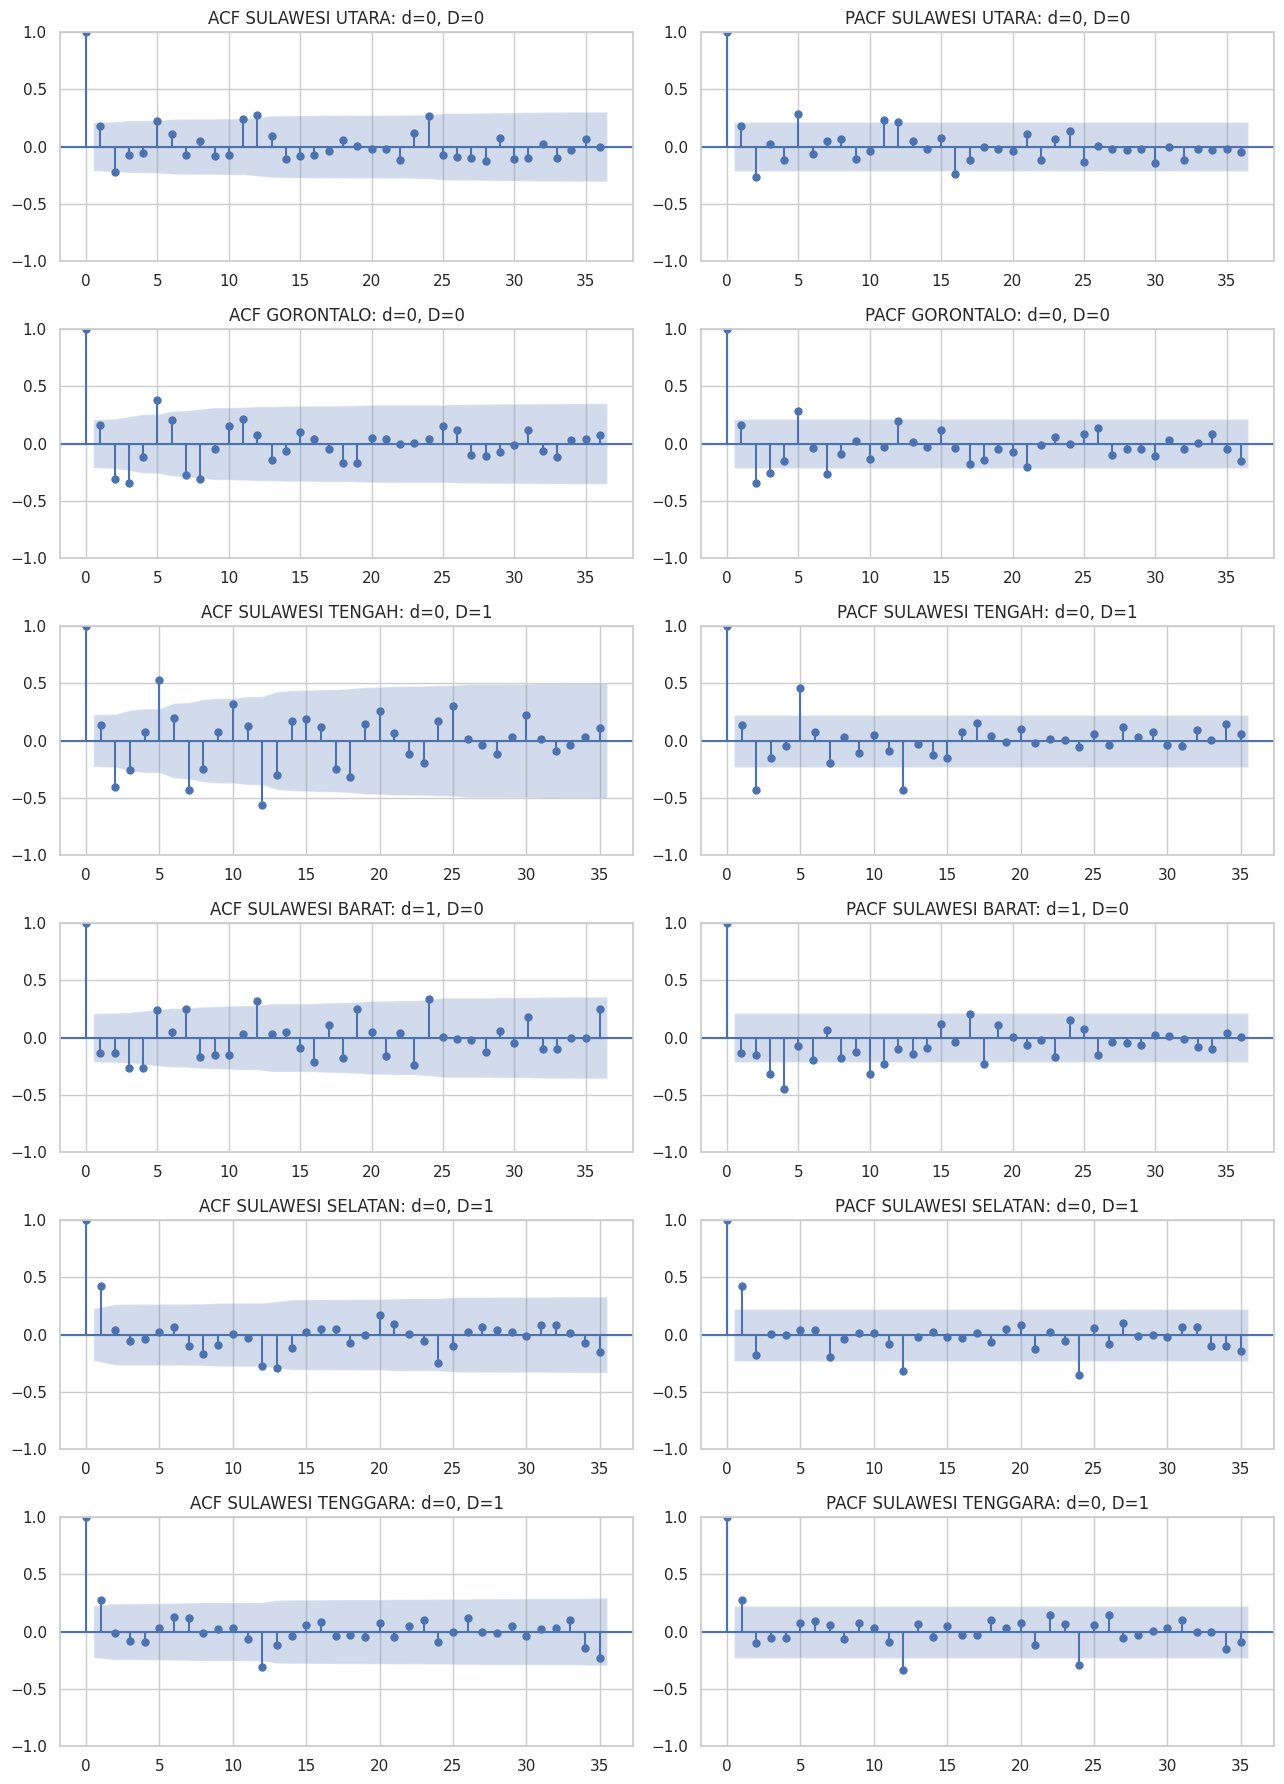

In [13]:
p=TOTAL
fig,axes=plt.subplots(2,2,figsize=(14,7))
for ax,(d,D) in zip(axes.ravel(),[(0,0),(1,0),(0,1),(1,1)]):
    s=tahap[p][(d,D)]
    s.plot(ax=ax);ax.axhline(s.mean(),ls="--",lw=.8,color="r")
    ax.set_title(f"Latih d={d},D={D}")
plt.tight_layout();plt.show()
d,D=orde_dD[p]
z=tahap[p][(d,D)]
nlags=min(36,len(z)//2-2)
fig,axes=plt.subplots(1,2,figsize=(14,4))
plot_acf(z,lags=nlags,ax=axes[0]);plot_pacf(z,lags=nlags,ax=axes[1],method="ywm")
axes[0].set_title(f"ACF {p} setelah d={d}, D={D}");axes[1].set_title("PACF")
plt.show()
# ACF/PACF untuk semua provinsi berdasarkan differencing masing-masing.
fig,axes=plt.subplots(len(PULAU),2,figsize=(13,3.0*len(PULAU)))
for i,p in enumerate(PULAU):
    d,D=orde_dD[p]
    z=tahap[p][(d,D)]
    nlag=min(36,max(6,len(z)//2-2))
    plot_acf(z,lags=nlag,ax=axes[i,0]);plot_pacf(z,lags=nlag,ax=axes[i,1],method="ywm")
    axes[i,0].set_title(f"ACF {p}: d={d}, D={D}")
    axes[i,1].set_title(f"PACF {p}: d={d}, D={D}")
plt.tight_layout();plt.show()

Gunakan ACF/PACF di atas sebagai petunjuk: lonjakan pada lag 1-2 menunjukkan p, q non-musiman; lonjakan pada lag 12, 24 menunjukkan P, Q musiman.

## 4. Identifikasi dan Estimasi Model

Grid standar menggunakan p,q = 0,1 dan P,Q = 0,1 (16 kandidat per model) dengan d,D yang dipilih pada **data latih**. Perbandingan SARIMA dan SARIMAX menggunakan rentang waktu latih identik, **Y dan transformasi yang sama**, serta syarat konvergensi. Data awal sebanyak 6 bulan dipotong dari semua model untuk ketersediaan lag eksogen dan keseimbangan perbandingan. **Lag X1 dan lag curah hujan** mengikuti pemilihan lag eksploratif sebelumnya.

Untuk penelitian, ruang model dapat diperluas ke p/q = 2 sebagai analisis sensitivitas, tetapi kandidat tambahan belum menjadi bagian dari hasil pengujian yang diberikan.


In [14]:
# Eksogen historis dengan lag terpilih untuk kedua variabel.
# Transformasi log1p eksogen tidak berkaitan dengan keputusan Box–Cox pada Y.
def exog_hist(p):
    return pd.DataFrame({
        "log1p_luas_panen_lag":np.log1p(data["X1"][p].shift(lag_terpilih[p]["X1"])),
        "log1p_hujan_lag":np.log1p(data["X2"][p].shift(lag_terpilih[p]["X2"]))
    },index=data[TARGET].index)

def split(p,use_exog):
    y=transform_y(data[TARGET][p].iloc[START_LAG:],p)
    ex=exog_hist(p).loc[y.index] if use_exog else None
    assert not y.isna().any()
    if ex is not None: assert not ex.isna().any().any()
    return y,ex

def fit(y,ex,order,sorder,maxiter=MAX_ITER_GRID):
    trend="n" if (order[1] or sorder[1]) else "c"
    m=SARIMAX(y,exog=ex,order=order,seasonal_order=sorder,
              trend=trend,enforce_stationarity=False,enforce_invertibility=False)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore",ConvergenceWarning)
        warnings.simplefilter("ignore",RuntimeWarning)
        return m.fit(disp=False,maxiter=maxiter)

def grid_search(y,ex,d,D,pmax=2,qmax=2,Pmax=1,Qmax=1):
    tabel=[];candidates=[]
    for p_,q_,P_,Q_ in itertools.product(range(pmax+1),range(qmax+1),range(Pmax+1),range(Qmax+1)):
        order=(p_,d,q_);so=(P_,D,Q_,S)
        try:
            r=fit(y,ex,order,so)
            conv=bool(r.mle_retvals.get("converged",False))
            tabel.append({"order":str(order),"seasonal":str(so),"AIC":r.aic,
                          "BIC":r.bic,"Konvergen":conv})
            if conv and np.isfinite(r.aic): candidates.append((r.aic,order,so,r))
        except (ValueError,np.linalg.LinAlgError,OverflowError,ZeroDivisionError):continue
    if not candidates:raise RuntimeError("Tidak ada model konvergen; periksa data atau tingkatkan iterasi")
    aic,order,so,res=min(candidates,key=lambda c:c[0])
    return (order,so,aic,res),pd.DataFrame(tabel).sort_values("AIC")

pilihan={}; model_train={}; grid_tabel={};order_rows=[]
for p in MODEL_PROV:
    d,D=orde_dD[p]
    for var,ue in [("SARIMA",False),("SARIMAX",True)]:
        y,ex=split(p,ue)
        tr_y=y.iloc[:-TEST];tr_ex=ex.iloc[:-TEST] if ex is not None else None
        best,tab=grid_search(tr_y,tr_ex,d,D,pmax=PMAX,qmax=QMAX,Pmax=SEASONAL_PMAX,Qmax=SEASONAL_QMAX)
        pilihan[(p,var)]=best[:3]
        model_train[(p,var)]=best[3]
        grid_tabel[(p,var)]=tab
        order_rows.append({"Provinsi":p,"Model":var,"order":str(best[0]),"seasonal":str(best[1]),
                           "AIC latih":best[2],"Kandidat konvergen":int(tab["Konvergen"].sum())})
        print(f"{p:19s} {var:7s} {best[0]} {best[1]} | AIC={best[2]:.2f}")
tabel_pilihan=pd.DataFrame(order_rows).set_index(["Provinsi","Model"])
display(tabel_pilihan)

SULAWESI UTARA      SARIMA  (1, 0, 1) (1, 0, 1, 12) | AIC=189.97
SULAWESI UTARA      SARIMAX (1, 0, 0) (0, 0, 0, 12) | AIC=-38.32
GORONTALO           SARIMA  (0, 0, 1) (1, 0, 1, 12) | AIC=205.28
GORONTALO           SARIMAX (1, 0, 0) (0, 0, 0, 12) | AIC=-19.10
SULAWESI TENGAH     SARIMA  (0, 0, 1) (0, 1, 1, 12) | AIC=122.60
SULAWESI TENGAH     SARIMAX (1, 0, 0) (0, 1, 0, 12) | AIC=-77.54
SULAWESI BARAT      SARIMA  (1, 1, 1) (1, 0, 1, 12) | AIC=160.63
SULAWESI BARAT      SARIMAX (1, 1, 1) (0, 0, 1, 12) | AIC=-62.13
SULAWESI SELATAN    SARIMA  (0, 0, 1) (0, 1, 1, 12) | AIC=44.99
SULAWESI SELATAN    SARIMAX (0, 0, 0) (0, 1, 1, 12) | AIC=-70.46
SULAWESI TENGGARA   SARIMA  (0, 0, 1) (0, 1, 1, 12) | AIC=97.39
SULAWESI TENGGARA   SARIMAX (1, 0, 0) (0, 1, 1, 12) | AIC=-24.08
TOTAL SULAWESI      SARIMA  (1, 0, 0) (0, 1, 1, 12) | AIC=43.14
TOTAL SULAWESI      SARIMAX (1, 0, 0) (0, 1, 0, 12) | AIC=-123.93


order       seasonal   AIC latih  \
Provinsi          Model                                           
SULAWESI UTARA    SARIMA   (1, 0, 1)  (1, 0, 1, 12)  189.971629   
                  SARIMAX  (1, 0, 0)  (0, 0, 0, 12)  -38.316007   
GORONTALO         SARIMA   (0, 0, 1)  (1, 0, 1, 12)  205.280268   
                  SARIMAX  (1, 0, 0)  (0, 0, 0, 12)  -19.104994   
SULAWESI TENGAH   SARIMA   (0, 0, 1)  (0, 1, 1, 12)  122.598283   
                  SARIMAX  (1, 0, 0)  (0, 1, 0, 12)  -77.536488   
SULAWESI BARAT    SARIMA   (1, 1, 1)  (1, 0, 1, 12)  160.627437   
                  SARIMAX  (1, 1, 1)  (0, 0, 1, 12)  -62.133265   
SULAWESI SELATAN  SARIMA   (0, 0, 1)  (0, 1, 1, 12)   44.991944   
                  SARIMAX  (0, 0, 0)  (0, 1, 1, 12)  -70.455586   
SULAWESI TENGGARA SARIMA   (0, 0, 1)  (0, 1, 1, 12)   97.390908   
                  SARIMAX  (1, 0, 0)  (0, 1, 1, 12)  -24.082141   
TOTAL SULAWESI    SARIMA   (1, 0, 0)  (0, 1, 1, 12)   43.137359   
                  SARIMAX  (1, 0, 0)  (0, 1, 0, 12) -123.929958   

                           Kandidat konvergen  
Provinsi          Model                        
SULAWESI UTARA    SARIMA                   13  
                  SARIMAX                  12  
GORONTALO         SARIMA                   16  
                  SARIMAX                  14  
SULAWESI TENGAH   SARIMA                   15  
                  SARIMAX                  16  
SULAWESI BARAT    SARIMA                   16  
                  SARIMAX                  15  
SULAWESI SELATAN  SARIMA                   15  
                  SARIMAX                  16  
SULAWESI TENGGARA SARIMA                   16  
                  SARIMAX                  16  
TOTAL SULAWESI    SARIMA                   15  
                  SARIMAX                  15

## 5. Evaluasi SARIMA dan SARIMAX pada Data Uji 12 Bulan

Evaluasi hanya membandingkan **SARIMA** dan **SARIMAX**. Keduanya dilatih dengan periode yang sama, kemudian menghasilkan ramalan untuk September 2025–Agustus 2026. Khusus SARIMAX, nilai X1/X2 yang diperlukan selama masa uji diproyeksikan dari data sebelum September 2025, bukan diambil dari nilai aktual bulan-bulan data uji. Hasil prediksi dari skala Box–Cox dikembalikan ke satuan Y asli sebelum menghitung **MAE, RMSE, MAPE, dan sMAPE**.


In [15]:
def metrik(a,f):
    a=np.asarray(a,dtype=float);f=np.asarray(f,dtype=float)
    assert np.isfinite(a).all() and np.isfinite(f).all()
    ae=np.abs(a-f)
    denom=np.abs(a)+np.abs(f)
    smape=100*np.mean(np.divide(2*ae,denom,out=np.zeros_like(ae),where=denom>0))
    mape=100*np.mean(ae/a) if (a>0).all() else np.nan
    return {"MAE":np.mean(ae),"RMSE":np.sqrt(np.mean((a-f)**2)),
            "MAPE (%)":mape,"sMAPE (%)":smape}

def kembali(v,p):
    """Invers transformasi Y per provinsi pada skala asli (median kondisional)."""
    a=np.asarray(v,dtype=float)*boxcox_status[p]["Skala_internal"]
    if boxcox_status[p]["Transformasi"]=="Box-Cox":
        lam=boxcox_status[p]["Lambda_dipakai"]
        shift=boxcox_status[p]["Shift"]
        # Invers hanya sah di domain 1 + lambda*z > 0.
        valid=(1+lam*a)>0 if abs(lam)>1e-10 else np.ones_like(a,dtype=bool)
        if not valid.all():
            warnings.warn(f"{p}: ada prediksi di luar domain invers Box-Cox; ditandai NaN. Tinjau orde/model.")
        z=np.where(valid,a,np.nan)
        result=inv_boxcox(z,lam)-shift
    else:
        result=a
    return np.maximum(result,0.0)  # proyeksi produksi tidak negatif

def proyeksi_exog(p, origin, tanggal_ramal):
    """Estimasi X1/X2 yang belum diketahui menggunakan informasi sampai origin.

    Proyeksi menggunakan rerata untuk bulan kalender yang sama selama 36 bulan
    sebelum origin. Lag eksogen pada bulan awal horizon tetap memakai histori
    yang sudah tersedia bila tanggal t-lag berada sebelum/tepat origin.
    """
    histori=seri[p].loc[:origin,EXOG]
    terakhir=histori.iloc[-36:]
    if len(terakhir)!=36:
        raise ValueError("Dibutuhkan sekurangnya 36 observasi historis X1/X2")
    masa_depan=pd.DataFrame(index=tanggal_ramal,columns=EXOG,dtype=float)
    for c in EXOG:
        rerata_bulanan=terakhir[c].groupby(terakhir.index.month).mean()
        masa_depan[c]=[rerata_bulanan[m] for m in tanggal_ramal.month]
    gabung=pd.concat([histori,masa_depan])
    ex=pd.DataFrame({
        "log1p_luas_panen_lag":np.log1p(gabung["X1"].shift(lag_terpilih[p]["X1"])).reindex(tanggal_ramal),
        "log1p_hujan_lag":np.log1p(gabung["X2"].shift(lag_terpilih[p]["X2"])).reindex(tanggal_ramal)
    },index=tanggal_ramal)
    if ex.isna().any().any():
        raise ValueError("Terdapat nilai eksogen hasil proyeksi yang hilang")
    return ex

idx_test=data[TARGET].index[-TEST:]
origin=data[TARGET].index[-TEST-1]
eval_rows=[];fc_test={}
for p in MODEL_PROV:
    aktual=data[TARGET][p].loc[idx_test]
    m_sarima=model_train[(p,"SARIMA")]
    m_sarimax=model_train[(p,"SARIMAX")]
    pred_sarima=kembali(m_sarima.get_forecast(TEST).predicted_mean,p)
    pred_sarimax=kembali(m_sarimax.get_forecast(TEST,exog=proyeksi_exog(p,origin,idx_test)).predicted_mean,p)
    for model,prediksi in [("SARIMA",pred_sarima),("SARIMAX",pred_sarimax)]:
        fc_test[(p,model)]=pd.Series(prediksi,index=idx_test)
        eval_rows.append({"Provinsi":p,"Model":model,**metrik(aktual,prediksi)})
evaluasi=pd.DataFrame(eval_rows).set_index(["Provinsi","Model"])
print("Evaluasi dua metode (MAE, RMSE, MAPE, sMAPE):")
display(evaluasi.round(2))

# Model terbaik per provinsi berdasarkan MAE; RMSE dan MAPE tetap dilaporkan.
model_pilih={};winner_rows=[]
for p in MODEL_PROV:
    a=evaluasi.loc[p]
    terbaik=a["MAE"].idxmin()
    model_pilih[p]=terbaik
    winner_rows.append({"Provinsi":p,"Model dipilih":terbaik,
                        "MAE terpilih":a.loc[terbaik,"MAE"],
                        "RMSE terpilih":a.loc[terbaik,"RMSE"],
                        "MAPE (%) terpilih":a.loc[terbaik,"MAPE (%)"],
                        "sMAPE (%) terpilih":a.loc[terbaik,"sMAPE (%)"]})
pemenang=pd.DataFrame(winner_rows).set_index("Provinsi")
print("Model dengan MAE terkecil pada setiap provinsi:")
display(pemenang.round(2))


Evaluasi dua metode (MAE, RMSE, MAPE, sMAPE):


MAE       RMSE  MAPE (%)  sMAPE (%)
Provinsi          Model                                             
SULAWESI UTARA    SARIMA     3475.02    4182.78     14.51      15.27
                  SARIMAX    2263.79    3261.81      9.62      10.64
GORONTALO         SARIMA     8919.03   11892.32     62.19      43.67
                  SARIMAX    7246.43    9633.28     44.13      35.33
SULAWESI TENGAH   SARIMA    20398.98   23733.24     27.68      29.92
                  SARIMAX   20854.32   24409.49     31.04      31.62
SULAWESI BARAT    SARIMA    10268.18   13229.55     27.58      31.10
                  SARIMAX    8395.75   10246.22     24.11      27.80
SULAWESI SELATAN  SARIMA    98649.45  133413.59     21.26      23.97
                  SARIMAX   94350.21  128509.12     21.34      22.89
SULAWESI TENGGARA SARIMA    10862.42   15387.33     20.01      23.55
                  SARIMAX   10529.47   15042.39     18.76      20.52
TOTAL SULAWESI    SARIMA   120710.95  157312.37     16.34      17.75
                  SARIMAX  123106.29  157595.82     17.10      18.19

Model dengan MAE terkecil pada setiap provinsi:


,Model dipilih,MAE terpilih,RMSE terpilih,MAPE (%) terpilih,sMAPE (%) terpilih
Provinsi,,,,,
SULAWESI UTARA,SARIMAX,2263.79,3261.81,9.62,10.64
GORONTALO,SARIMAX,7246.43,9633.28,44.13,35.33
SULAWESI TENGAH,SARIMA,20398.98,23733.24,27.68,29.92
SULAWESI BARAT,SARIMAX,8395.75,10246.22,24.11,27.80
SULAWESI SELATAN,SARIMAX,94350.21,128509.12,21.34,22.89
SULAWESI TENGGARA,SARIMAX,10529.47,15042.39,18.76,20.52
TOTAL SULAWESI,SARIMA,120710.95,157312.37,16.34,17.75


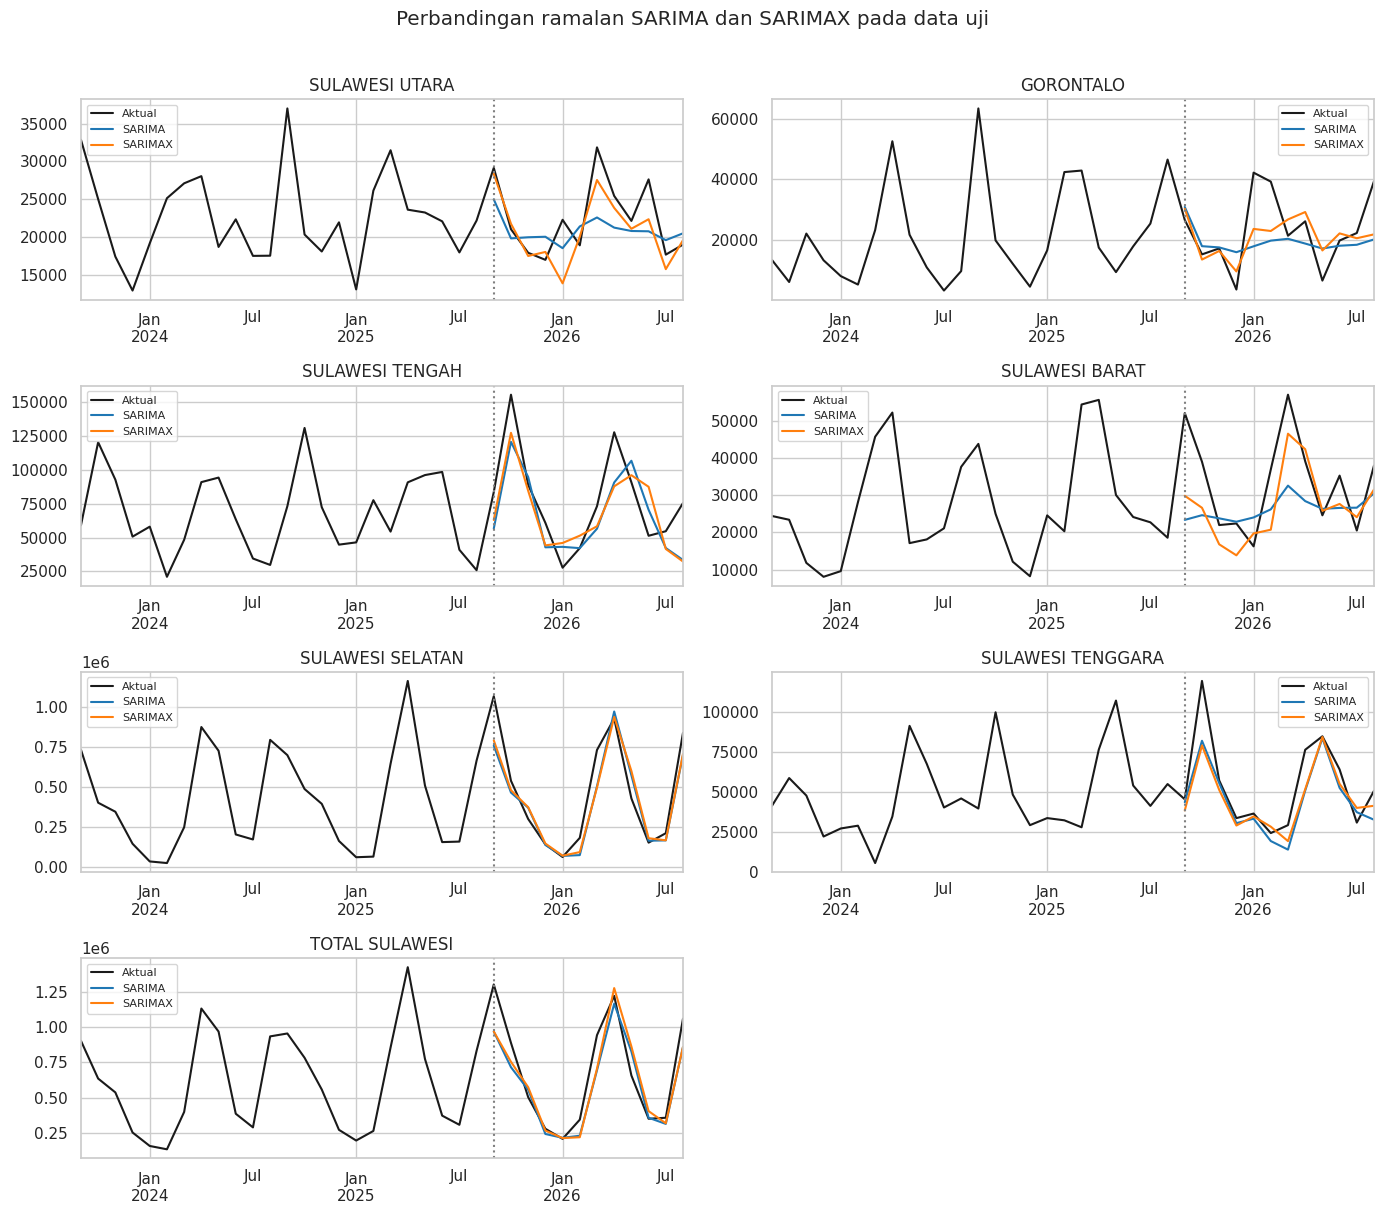

In [16]:
fig,axes=plt.subplots(math.ceil(len(MODEL_PROV)/2),2,figsize=(14,12))
for ax,p in zip(axes.ravel(),MODEL_PROV):
    data[TARGET][p].iloc[-36:].plot(ax=ax,color="k",label="Aktual")
    for nama,warna in [("SARIMA","tab:blue"),("SARIMAX","tab:orange")]:
        fc_test[(p,nama)].plot(ax=ax,color=warna,label=nama)
    ax.axvline(idx_test[0],color="gray",ls=":")
    ax.set_title(p)
    ax.legend(fontsize=8)
for ax in axes.ravel()[len(MODEL_PROV):]:
    ax.axis("off")
plt.suptitle("Perbandingan ramalan SARIMA dan SARIMAX pada data uji",y=1.01)
plt.tight_layout();plt.show()


**Interpretasi evaluasi:** Nilai MAE, RMSE, MAPE dan sMAPE yang lebih kecil mengindikasikan prediksi lebih akurat pada data uji. Pemilihan metode otomatis di notebook memakai **MAE terendah**; RMSE dan MAPE ditampilkan untuk melihat apakah kesimpulannya konsisten. Jika metrik berbeda arah, bahas perbedaannya secara terbuka. Satu pembagian data latih-uji tidak menggantikan validasi bergulir (*rolling-origin*).

**Perhatian pada MAPE:** Jika Y aktual bernilai 0, MAPE tidak terdefinisi dan ditampilkan `NaN`; jangan menafsirkan nilainya sebagai 0%. Jika Y sangat kecil, MAPE dapat menjadi sangat besar.


## 6. Diagnostik Residual

N residual  Konvergen  LB p lag 12  LB p lag 24  \
Provinsi          Model                                                      
SULAWESI UTARA    SARIMA           72       True       0.0065       0.0064   
                  SARIMAX          74       True       0.5542       0.8871   
GORONTALO         SARIMA           72       True       0.0000       0.0000   
                  SARIMAX          74       True       0.1275       0.1348   
SULAWESI TENGAH   SARIMA           60       True       0.0014       0.0591   
                  SARIMAX          73       True       0.2799       0.6307   
SULAWESI BARAT    SARIMA           71       True       0.0100       0.0098   
                  SARIMAX          71       True       0.0373       0.3390   
SULAWESI SELATAN  SARIMA           60       True       0.3887       0.6384   
                  SARIMAX          61       True       0.1403       0.2824   
SULAWESI TENGGARA SARIMA           60       True       0.8379       0.8350   
                  SARIMAX          61       True       0.5766       0.4455   
TOTAL SULAWESI    SARIMA           61       True       0.2233       0.3866   
                  SARIMAX          73       True       0.1307       0.2690   

                             JB p  
Provinsi          Model            
SULAWESI UTARA    SARIMA   0.5779  
                  SARIMAX  0.0004  
GORONTALO         SARIMA   0.4003  
                  SARIMAX  0.0000  
SULAWESI TENGAH   SARIMA   0.9073  
                  SARIMAX  0.1427  
SULAWESI BARAT    SARIMA   0.2650  
                  SARIMAX  0.0000  
SULAWESI SELATAN  SARIMA   0.2053  
                  SARIMAX  0.0875  
SULAWESI TENGGARA SARIMA   0.6387  
                  SARIMAX  0.2519  
TOTAL SULAWESI    SARIMA   0.4292  
                  SARIMAX  0.4837

Ringkasan pemilihan akurasi dan diagnostik residual:


,Model dipilih,MAE terpilih,RMSE terpilih,MAPE (%) terpilih,sMAPE (%) terpilih,LB12 p (model pilihan),LB24 p (model pilihan),JB p (model pilihan),Residual putih pada lag 12/24?,Catatan diagnostik
Provinsi,,,,,,,,,,
SULAWESI UTARA,SARIMAX,2263.7882,3261.8122,9.6223,10.6396,0.5542,0.8871,0.0004,True,Tidak terdeteksi autokorelasi pada lag uji
GORONTALO,SARIMAX,7246.4256,9633.2833,44.1320,35.3277,0.1275,0.1348,0.0000,True,Tidak terdeteksi autokorelasi pada lag uji
SULAWESI TENGAH,SARIMA,20398.9839,23733.2369,27.6752,29.9159,0.0014,0.0591,0.9073,False,PERLU REVISI: residu masih berautokorelasi
SULAWESI BARAT,SARIMAX,8395.7537,10246.2153,24.1098,27.7991,0.0373,0.3390,0.0000,False,PERLU REVISI: residu masih berautokorelasi
SULAWESI SELATAN,SARIMAX,94350.2118,128509.1214,21.3350,22.8853,0.1403,0.2824,0.0875,True,Tidak terdeteksi autokorelasi pada lag uji
SULAWESI TENGGARA,SARIMAX,10529.4727,15042.3853,18.7554,20.5157,0.5766,0.4455,0.2519,True,Tidak terdeteksi autokorelasi pada lag uji
TOTAL SULAWESI,SARIMA,120710.9543,157312.3746,16.3439,17.7489,0.2233,0.3866,0.4292,True,Tidak terdeteksi autokorelasi pada lag uji


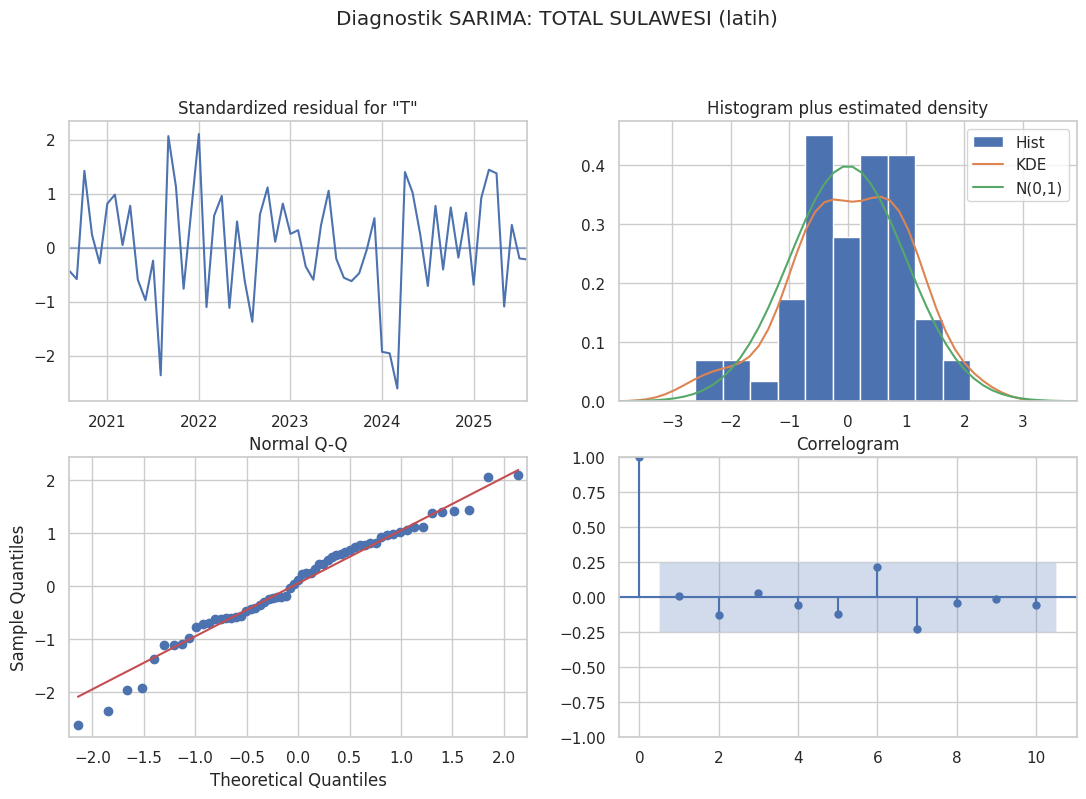

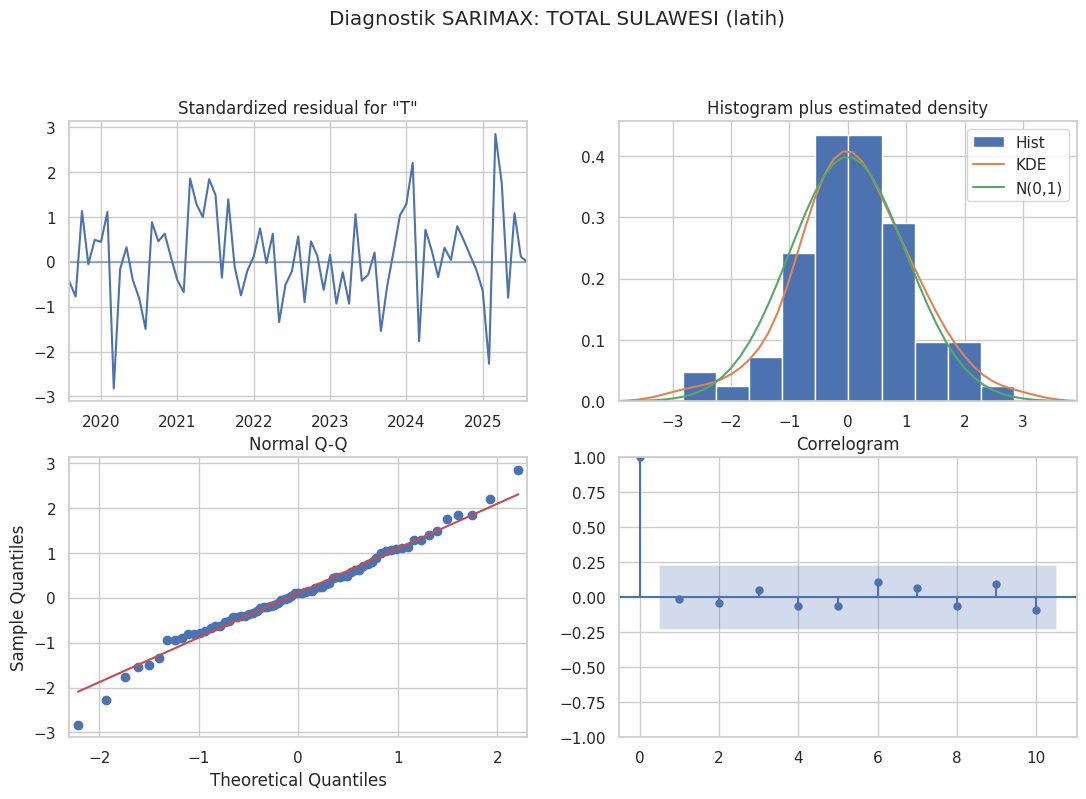

In [17]:
def diagnostik(r,p,var):
    # standardized_forecasts_error mengurangi persoalan skala dan varians yang berubah.
    burn=max(S,int(getattr(r,"loglikelihood_burn",0)))
    res=np.asarray(r.filter_results.standardized_forecasts_error[0],dtype=float)[burn:]
    res=res[np.isfinite(res)]
    order,sorder,_=pilihan[(p,var)]
    # Derajat bebas Ljung-Box untuk bagian AR/MA reguler dan musiman.
    df_model=order[0]+order[2]+sorder[0]+sorder[2]
    use_lags=[l for l in [12,24] if l>df_model and l<len(res)]
    lb=acorr_ljungbox(res,lags=use_lags,model_df=df_model,return_df=True) if use_lags else None
    return {"Provinsi":p,"Model":var,"N residual":len(res),
            "Konvergen":bool(r.mle_retvals.get("converged",False)),
            "LB p lag 12":lb.loc[12,"lb_pvalue"] if lb is not None and 12 in lb.index else np.nan,
            "LB p lag 24":lb.loc[24,"lb_pvalue"] if lb is not None and 24 in lb.index else np.nan,
            "JB p":jarque_bera(res)[1] if len(res)>8 and np.std(res)>0 else np.nan}

dg=pd.DataFrame([diagnostik(model_train[(p,var)],p,var) for p in MODEL_PROV
                 for var in ["SARIMA","SARIMAX"]]).set_index(["Provinsi","Model"])
display(dg.round(4))
# Kaitkan kualitas diagnostik model yang dipilih melalui MAE dengan tabel kesimpulan.
for kolom, src in [("LB12 p (model pilihan)","LB p lag 12"),
                   ("LB24 p (model pilihan)","LB p lag 24"),
                   ("JB p (model pilihan)","JB p")]:
    pemenang[kolom] = [dg.loc[(p,model_pilih[p]),src] for p in MODEL_PROV]
pemenang["Residual putih pada lag 12/24?"] = [
    bool(pd.notna(pemenang.loc[p,"LB12 p (model pilihan)"])
         and pd.notna(pemenang.loc[p,"LB24 p (model pilihan)"])
         and pemenang.loc[p,"LB12 p (model pilihan)"]>=0.05
         and pemenang.loc[p,"LB24 p (model pilihan)"]>=0.05)
    for p in MODEL_PROV]
pemenang["Catatan diagnostik"] = np.where(
    pemenang["Residual putih pada lag 12/24?"],
    "Tidak terdeteksi autokorelasi pada lag uji",
    "PERLU REVISI: residu masih berautokorelasi")
print("Ringkasan pemilihan akurasi dan diagnostik residual:")
display(pemenang.round(4))
for var in ["SARIMA","SARIMAX"]:
    r=model_train[(TOTAL,var)]
    r.plot_diagnostics(figsize=(13,8));plt.suptitle(f"Diagnostik {var}: {TOTAL} (latih)",y=1.02);plt.show()

**Interpretasi:** Ljung-Box p > 0,05 = **tidak cukup bukti** autokorelasi hingga lag tersebut, bukan bukti residual pasti independen. Jarque-Bera p > 0,05 = normalitas residual tidak ditolak. Ljung-Box telah menyesuaikan derajat bebas untuk p+q+P+Q. Jika p kecil, model masih menyisakan pola dan perlu perbaikan; jangan menyatakan lolos diagnostik untuk semua provinsi. Semua angka dihitung pada data latih.

**Catatan:** pemilihan model berdasarkan MAE tidak dengan sendirinya menjamin residual lolos Ljung–Box. Model yang gagal uji residual ditandai pada `Model_Terpilih` dan **perlu diperbaiki sebelum digunakan untuk kesimpulan inferensial**. Dalam laporan, akurasi dan kecukupan model harus disajikan terpisah; selang ramalan normal juga perlu diinterpretasi hati-hati bila Jarque–Bera ditolak.


## 7. Peramalan 12 Bulan ke Depan

Sesudah membandingkan hanya **SARIMA** dan **SARIMAX** berdasarkan MAE pada data uji, model dengan MAE terkecil diestimasi ulang pada seluruh data yang tersedia. Orde, lag, dan parameter transformasi dipertahankan dari keputusan pada data latih awal. Ramalan dibuat untuk 12 bulan, September 2026–Agustus 2027. Jika model terpilih SARIMAX, X1/X2 masa depan diproyeksikan dengan pendekatan rerata bulan kalender dari 36 bulan historis terakhir.


**Asumsi ketersediaan X1 dan X2:** Untuk meramal bulan yang belum terjadi, data luas panen dan curah hujan bulan tersebut belum tersedia. Oleh karena itu, notebook menggunakan proyeksi sederhana berbasis rerata historis per bulan kalender selama tiga tahun. Proyeksi ini dipakai secara konsisten dalam SARIMAX pada periode data uji maupun periode masa depan, tidak menggunakan nilai eksogen aktual yang baru diketahui setelah bulan target. Interval prediksi SARIMAX belum memasukkan ketidakpastian proyeksi X1/X2; hasil perlu dilaporkan sebagai ramalan dengan asumsi eksogen tersebut.


Periode ramalan: 2026-09 s.d. 2027-08


,Metode,Konvergen full
Provinsi,,
SULAWESI UTARA,SARIMAX,True
GORONTALO,SARIMAX,True
SULAWESI TENGAH,SARIMA,True
SULAWESI BARAT,SARIMAX,True
SULAWESI SELATAN,SARIMAX,True
SULAWESI TENGGARA,SARIMAX,True
TOTAL SULAWESI,SARIMA,True


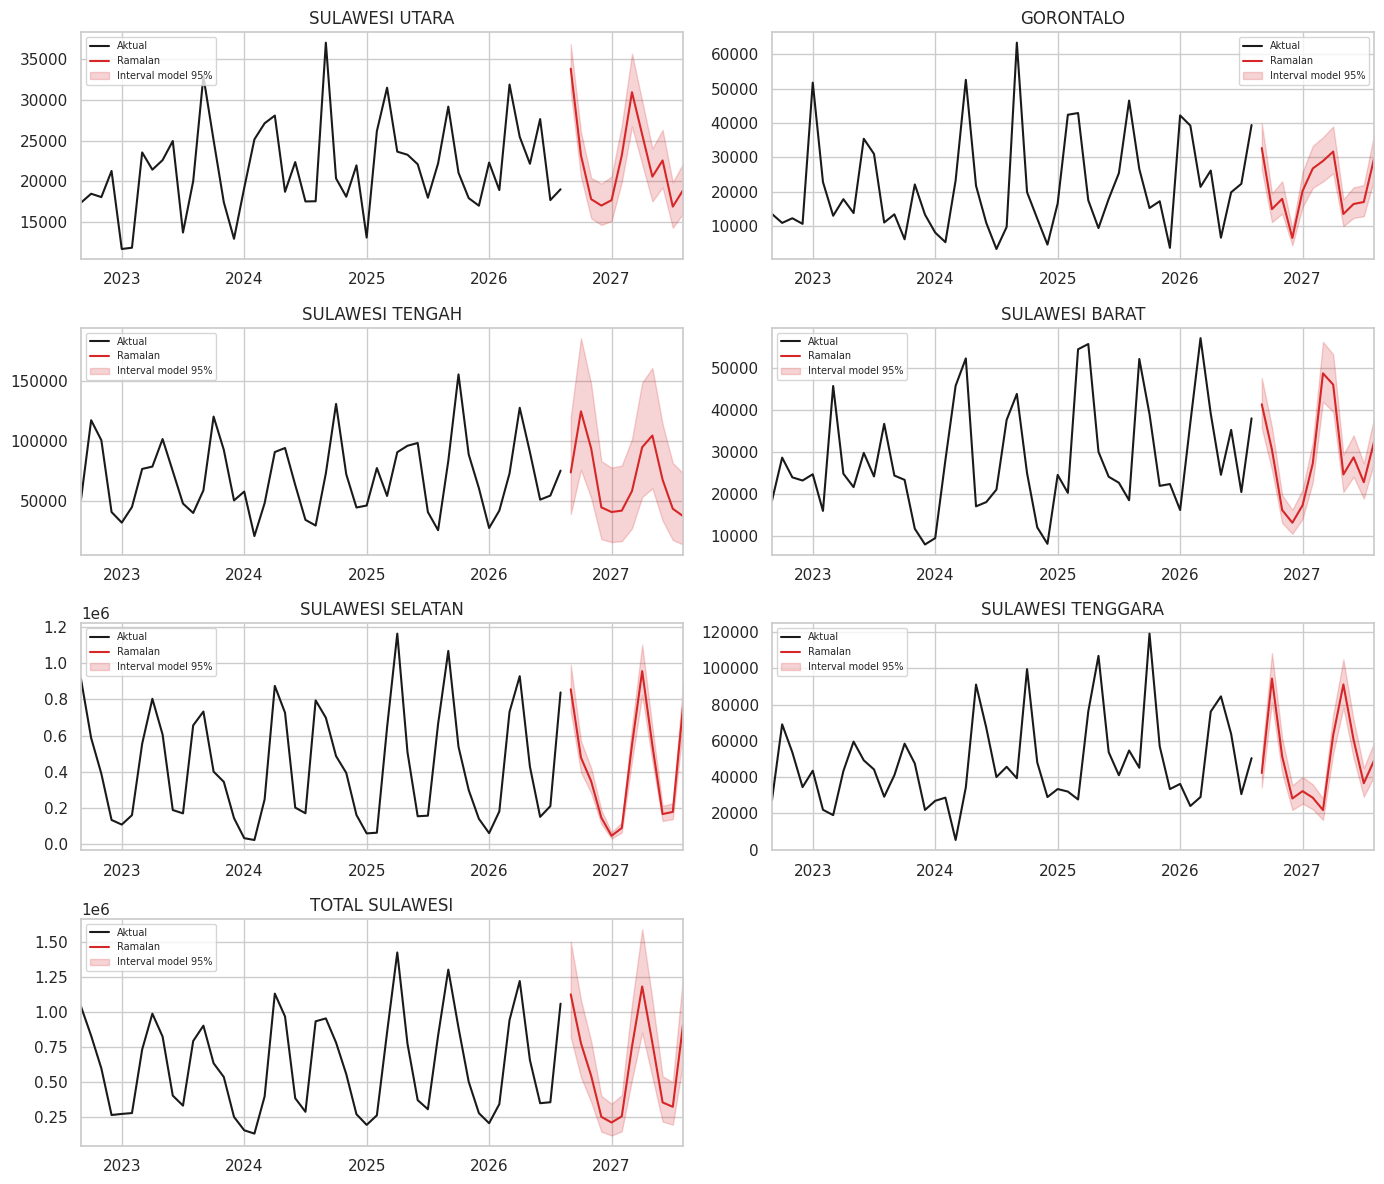

,Ramalan,Bawah 95%,Atas 95%,Metode
2026-09-01,1127863.0,822225.0,1504127.0,SARIMA
2026-10-01,778422.0,535647.0,1088193.0,SARIMA
2026-11-01,545507.0,357719.0,792264.0,SARIMA
2026-12-01,251685.0,145726.0,401599.0,SARIMA
2027-01-01,211508.0,118475.0,345682.0,SARIMA
2027-02-01,255509.0,148347.0,406882.0,SARIMA
2027-03-01,754311.0,516155.0,1059236.0,SARIMA
2027-04-01,1184424.0,853764.0,1594374.0,SARIMA
2027-05-01,780174.0,536085.0,1091893.0,SARIMA
2027-06-01,355062.0,218199.0,542036.0,SARIMA


In [18]:
last=data[TARGET].index[-1]
fidx=pd.date_range(last+pd.offsets.MonthBegin(1),periods=H,freq="MS")
hasil_fc={};model_final={};full_conv=[]
for p in MODEL_PROV:
    var=model_pilih[p]
    y,ex=split(p,var=="SARIMAX")
    order,sorder,_=pilihan[(p,var)]
    r=fit(y,ex,order,sorder,maxiter=300)
    converged=bool(r.mle_retvals.get("converged",False))
    full_conv.append({"Provinsi":p,"Metode":var,"Konvergen full":converged})
    if not converged: warnings.warn(f"Final {p} {var} belum konvergen; ramalan perlu diverifikasi")
    ef=proyeksi_exog(p,last,fidx) if var=="SARIMAX" else None
    fc=r.get_forecast(H,exog=ef)
    ci=fc.conf_int(alpha=.05)
    hasil_fc[p]=pd.DataFrame({"Ramalan":kembali(fc.predicted_mean,p),
                              "Bawah 95%":kembali(ci.iloc[:,0],p),
                              "Atas 95%":kembali(ci.iloc[:,1],p),
                              "Metode":var},index=fidx)
    model_final[p]=r

print("Periode ramalan:",fidx[0].strftime("%Y-%m"),"s.d.",fidx[-1].strftime("%Y-%m"))
display(pd.DataFrame(full_conv).set_index("Provinsi"))
fig,axes=plt.subplots(math.ceil(len(MODEL_PROV)/2),2,figsize=(14,12))
for ax,p in zip(axes.ravel(),MODEL_PROV):
    data[TARGET][p].iloc[-48:].plot(ax=ax,color="k",label="Aktual")
    hasil_fc[p]["Ramalan"].plot(ax=ax,color="tab:red",label="Ramalan")
    ax.fill_between(fidx,hasil_fc[p]["Bawah 95%"],hasil_fc[p]["Atas 95%"],
                    color="tab:red",alpha=.2,label="Interval model 95%")
    ax.set_title(p);ax.legend(fontsize=7)
for ax in axes.ravel()[len(MODEL_PROV):]:ax.axis("off")
plt.tight_layout();plt.show()
display(hasil_fc[TOTAL].round(0))

In [19]:
rg=[]
for p in MODEL_PROV:
    a=data[TARGET][p].iloc[-12:].sum();b=hasil_fc[p]["Ramalan"].sum()
    rg.append({"Provinsi":p,"Metode":model_pilih[p],"Total 12 bln terakhir (aktual)":a,
               "Total 12 bln ke depan (ramalan)":b,"Perubahan (%)":(b/a-1)*100 if a>0 else np.nan})
ringkasan=pd.DataFrame(rg).set_index("Provinsi")
display(ringkasan.round(1))
# TOTAL dimodelkan tersendiri sehingga belum tentu sama dengan jumlah ramalan provinsi.
# Sediakan agregat bottom-up untuk kebutuhan identitas penjumlahan.
additive=pd.concat([hasil_fc[p]["Ramalan"].rename(p) for p in PULAU],axis=1).sum(axis=1)
perbandingan_total=pd.DataFrame({"Model total terpisah":hasil_fc[TOTAL]["Ramalan"],
                                  "Jumlah 6 model provinsi":additive})
display(perbandingan_total.round(0))

,Metode,Total 12 bln terakhir (aktual),Total 12 bln ke depan (ramalan),Perubahan (%)
Provinsi,,,,
SULAWESI UTARA,SARIMAX,270236.1,268322.1,-0.7
GORONTALO,SARIMAX,279720.4,256016.2,-8.5
SULAWESI TENGAH,SARIMA,932526.5,828566.8,-11.1
SULAWESI BARAT,SARIMAX,403408.8,349521.3,-13.4
SULAWESI SELATAN,SARIMAX,5579155.6,5121321.2,-8.2
SULAWESI TENGGARA,SARIMAX,649975.3,599881.7,-7.7
TOTAL SULAWESI,SARIMA,8115022.7,7476822.9,-7.9


,Model total terpisah,Jumlah 6 model provinsi
2026-09-01,1127863.0,1080187.0
2026-10-01,778422.0,766906.0
2026-11-01,545507.0,545574.0
2026-12-01,251685.0,256709.0
2027-01-01,211508.0,175601.0
2027-02-01,255509.0,238010.0
2027-03-01,754311.0,737247.0
2027-04-01,1184424.0,1218168.0
2027-05-01,780174.0,801551.0
2027-06-01,355062.0,363291.0


## 8. Ekspor Hasil Excel

Hasil meliputi tabel Box–Cox (λ, interval kepercayaan, shift, keputusan), lag X1 dan hujan terpilih, CCF semua kandidat, stasioneritas ADF/KPSS, AIC/model terbaik, holdout, diagnostik, dan ramalan tiap provinsi. **Profil likelihood dan grafik perbandingan sebelum/sesudah Box–Cox ditampilkan di notebook ketika dijalankan.** Angka hasil notebook sebelumnya tidak dibawa karena spesifikasi dan transformasi berbeda.

Tabel `Model_Terpilih` juga memuat hasil uji Ljung–Box pada residual model ber-MAE terbaik, supaya ketidakcukupan model tidak tersembunyi.


In [20]:
filename=f"hasil_LAG_BOXCOX_sarima_sarimax_{PULAU_PILIH.lower()}.xlsx"
with pd.ExcelWriter(filename) as w:
    ringkas.to_excel(w,sheet_name="EDA")
    pd.DataFrame({"Provinsi":PULAU,"Bulan tersedia":[len(seri[p]) for p in PULAU],"Awal":[str(seri[p].index.min().date()) for p in PULAU],"Akhir":[str(seri[p].index.max().date()) for p in PULAU]}).to_excel(w,sheet_name="Validasi_Data",index=False)
    tabel_stl.to_excel(w,sheet_name="STL_Latih")
    kor.to_excel(w,sheet_name="Korelasi_Latih")
    tabel_boxcox.to_excel(w,sheet_name="BoxCox_Latih")
    tabel_lag.to_excel(w,sheet_name="Lag_CCF_Latih",index=False)
    tabel_lag_pilih.to_excel(w,sheet_name="Lag_Terpilih")
    tabel_stas.to_excel(w,sheet_name="Stasioner_Latih")
    tabel_orde.to_excel(w,sheet_name="Orde_dD")
    tabel_pilihan.to_excel(w,sheet_name="AIC_Latih")
    evaluasi.to_excel(w,sheet_name="Evaluasi_12_Bulan")
    pemenang.to_excel(w,sheet_name="Model_Terpilih")
    dg.to_excel(w,sheet_name="Diagnostik")
    ringkasan.to_excel(w,sheet_name="Ringkasan")
    perbandingan_total.to_excel(w,sheet_name="Total_Dua_Cara")
    for i,p in enumerate(MODEL_PROV):
        hasil_fc[p].to_excel(w,sheet_name=f"Ramalan_{i+1}_{p[:18]}")
try:
    from google.colab import files
    files.download(filename)
except ImportError:
    print("File disimpan di:",filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>